In [ ]:
import sys
from pathlib import Path
import numpy as np

import os
os.chdir("d:/kurssit/Dippatyo/tutkielma/soccer_hmm_project/")

project_root = Path().resolve().parent
sys.path.append(str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.soccer_hmm.config import PROCESSED_DATA_DIR, RAW_DATA_DIR, STAN_DIR
from src.soccer_hmm.dataset import process_raw_data
from cmdstanpy import from_csv
from cmdstanpy import CmdStanModel

input_path: Path = RAW_DATA_DIR
output_path_1: Path = PROCESSED_DATA_DIR / "soccerdata_processed.csv"
output_path_2: Path = PROCESSED_DATA_DIR / "soccerdata_processed_1.csv"

processed_data_file_1 = PROCESSED_DATA_DIR / "soccerdata_processed_floor.csv"
processed_data_file_2 = PROCESSED_DATA_DIR / "soccerdata_processed_ceil.csv"

raw_data_file = RAW_DATA_DIR / "raw_n12_m17.csv"

stan_path: Path = STAN_DIR / "soccer_hmm_2.stan"

In [18]:
a = np.arange(4000)
len(a[::10])

400

In [2]:
process_raw_data(input_path, output_path_1)

2026-08-17 18:21:47.114 | INFO     | src.soccer_hmm.dataset:process_raw_data:581 - Processing dataset...
2026-08-17 18:21:47.114 | INFO     | src.soccer_hmm.dataset:make_data_dict:566 - Processing file Game_1_hyökkääjä_JM_Catapult-Export-1770541727119.csv...
Setting start to NaN until index 2025-08-20 20:05:42
Setting end to NaN from index 2025-08-20 20:47:46
Idle periods: 0
No idle periods detected.
2026-08-17 18:21:47.265 | INFO     | src.soccer_hmm.dataset:make_data_dict:575 - File <DirEntry 'Game_1_hyökkääjä_JM_Catapult-Export-1770541727119.csv'> processed succesfully
2026-08-17 18:21:47.265 | INFO     | src.soccer_hmm.dataset:make_data_dict:566 - Processing file Game_1_hyökkääjä_NN_Catapult-Export-1770541853306.csv...
Setting start to NaN until index 2025-08-20 20:01:38
Setting end to NaN from index 2025-08-20 21:46:32
Idle periods: 1
Removed idle period from 2025-08-20 20:47:40 to 2025-08-20 21:02:26 lasting 14.77 minutes.
2026-08-17 18:21:47.450 | INFO     | src.socc

(      index           timestamp          x          y     speed  playerload  \
 0     53469 2025-07-01 20:01:04 -14.445806   9.940975  4.230256    1.178726   
 1     53470 2025-07-01 20:01:06 -18.012696  10.166212  3.266248    1.232081   
 2     53471 2025-07-01 20:01:08 -20.371659   9.692832  1.989460    0.530968   
 3     53472 2025-07-01 20:01:10 -21.642162   9.089655  1.111787    0.261673   
 4     53473 2025-07-01 20:01:12 -21.655436   8.020733  1.591791    0.855463   
 ...     ...                 ...        ...        ...       ...         ...   
 8273  92342 2025-05-16 21:46:58 -17.800435  24.493585  5.956492    1.258384   
 8274  92343 2025-05-16 21:47:00 -18.625495  35.178987  5.083152    1.281016   
 8275  92344 2025-05-16 21:47:02 -20.357173  44.444251  4.500147    1.192492   
 8276  92345 2025-05-16 21:47:04 -21.481910  46.765339  1.253899    0.259109   
 8277  92346 2025-05-16 21:47:06 -20.463388  43.642559  2.743133    1.048384   
 
       accelrate  track_id game   posi

In [12]:
from scipy.stats import circmean
def circular_acf(x, k=1):
    """
    Computes the circular autocorrelation for a given lag.

    Args:
        alpha: array-like, circular variable (in radians)
        k: int, lag for autocorrelation

    Returns:
        float: Circular autocorrelation coefficient
    """
    T = len(x)
    if k >= T:
        raise ValueError("Lag must be less than the length of the data.")

    if k == 0:
        return 1.0  # Autocorrelation at lag 0 is always 1

    muhat = circmean(x, low=-np.pi, high=np.pi)

    return np.sum(np.sin(x - muhat)[:T-k] * np.sin(x - muhat)[k:]) / np.sum(np.sin(x - muhat)**2)

In [ ]:
processed_data = pd.read_csv(output_path_1)
processed_data = processed_data[(processed_data["player_id"] == 18)]

In [ ]:
processed_data.shape

In [15]:
processed_data["track_id"].unique()

array([24, 33, 38])

In [18]:
processed_data = pd.read_csv(output_path_1)
processed_data = processed_data[(processed_data["player_id"] == 18) & (processed_data["track_id"] == 24)]

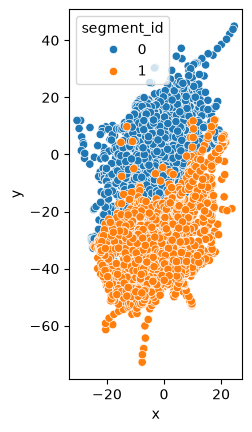

In [21]:
ax = sns.scatterplot(data=processed_data, x="x", y="y", hue="segment_id", )
ax.set_aspect('equal')

In [13]:
processed_data["x"].describe()

count    2861.000000
mean       -2.824824
std        10.919626
min       -30.473104
25%       -10.061624
50%        -3.079547
75%         4.985301
max        24.588970
Name: x, dtype: float64

<Axes: xlabel='speed', ylabel='accelrate'>

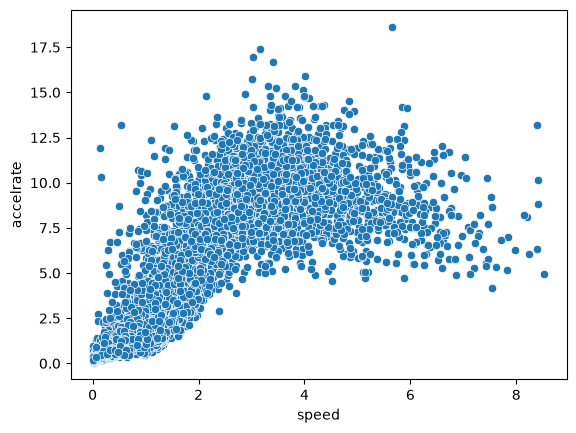

In [7]:
sns.scatterplot(data=processed_data[["accelrate", "speed"]], x="speed", y="accelrate")

In [3]:
processed_data[["speed", "accelrate", "turn_angle"]].describe()

,speed,accelrate,turn_angle
count,8278.000000,8278.000000,8278.000000
mean,1.936405,4.866622,0.000111
std,1.438067,3.787512,1.019839
min,0.010000,0.036224,-3.141593
25%,0.944730,1.434140,-0.329049
50%,1.554735,3.663792,0.001350
75%,2.786356,8.321298,0.335562
max,8.524846,18.634503,3.139799


<Axes: >

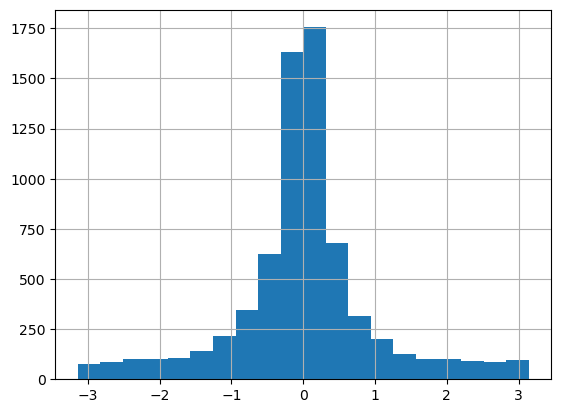

In [14]:
processed_data[processed_data["accelrate"] > 1]["turn_angle"].hist(bins=20)

<Axes: >

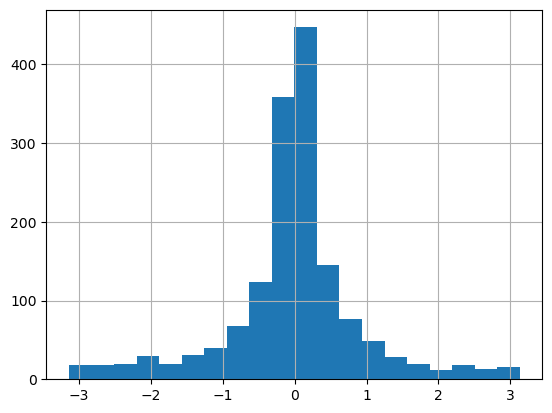

In [11]:
processed_data[(processed_data["accelrate"] < 2) & (processed_data["accelrate"] > 1)]["turn_angle"].hist(bins=20)

<Axes: >

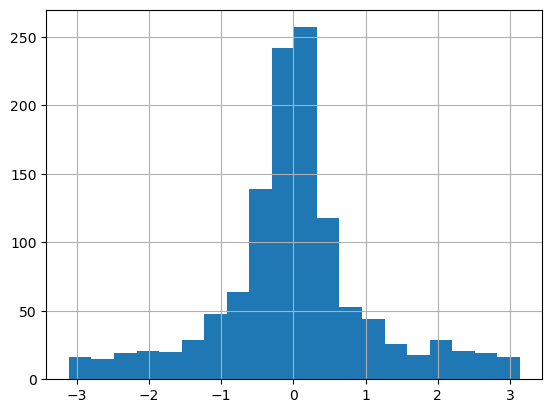

In [7]:
processed_data[(processed_data["speed"] < 3) & (processed_data["speed"] > 2)]["turn_angle"].hist(bins=20)

<Axes: >

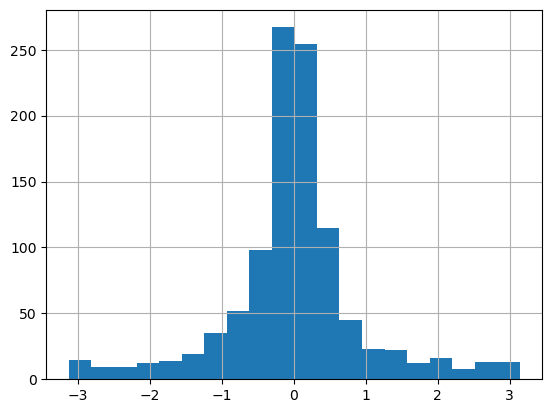

In [8]:
processed_data[(processed_data["speed"] < 4) & (processed_data["speed"] > 3)]["turn_angle"].hist(bins=20)

In [1]:
a = [1, 2, 3]

In [2]:
a[0:0]

[]

<Axes: >

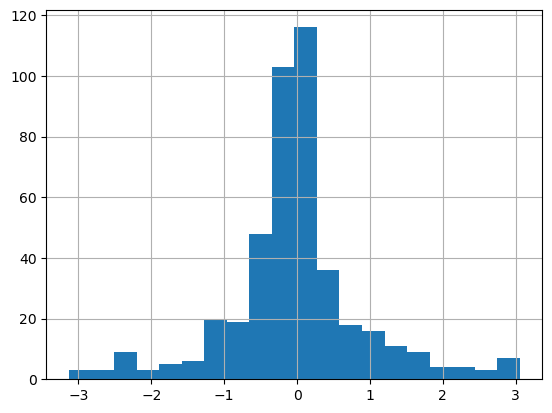

In [9]:
processed_data[(processed_data["speed"] < 5) & (processed_data["speed"] > 4)]["turn_angle"].hist(bins=20)

In [6]:
model = CmdStanModel(stan_file=stan_path,
                     #exe_file=exe_path,
                     cpp_options={"STAN_THREADS":"true"})

rng_seed = 67

n_states=5

inits_template = {
    "mu_speeds":    None,
    "sigma_speeds": None,
    "mu_loads":     None,
    "sigma_loads":  None,
    "xangle":       None,
    "yangle":       None,
    "beta":         None
}
chain_inits = []
rng = np.random.default_rng(rng_seed)


inits = inits_template.copy()
inits["mu_speeds"] = [0.5, 1.25, 2.0, 2.75, 3.5]

inits["sigma_speeds"] = [0.5, 0.5, 0.5, 0.5, 0.5]
inits["mu_loads"] = [1, 2, 3, 4, 5]

inits["sigma_loads"] = [0.5, 0.5, 0.5, 0.5, 0.5]

inits["xangle"] = [5, 5, 5, 5, 5]
inits["yangle"] = [0, 0, 0, 0, 0]

inits["beta"] = np.full((n_states*(n_states-1), 2), 0)

X = np.column_stack([
        np.ones(processed_data.shape[0]),
        processed_data["accelrate_cumulative_30s_z"].to_numpy()
])

#Construct the data-dictionary for the model
modeling_data = dict({
    "T": processed_data.shape[0],
    "N_tracks": len(processed_data["track_id"].unique()),
    "track_ID": processed_data["track_id"].to_numpy(),
    "segment_ID": processed_data["segment_id"].to_numpy(),
    "speeds": processed_data["speed"].to_numpy(),
    "loads": processed_data["accelrate"].to_numpy(),
    "angles": processed_data["turn_angle"].to_numpy(),
    "N": n_states,
    "nCovs": 1,
    "covs": X
})

mle = model.optimize(
    data=modeling_data,
    seed=rng_seed,
    inits=inits,
    show_console=True,
    jacobian=True,
    iter=1000
)

18:23:16 - cmdstanpy - INFO - Chain [1] start processing


Chain [1] method = optimize
Chain [1] optimize
Chain [1] algorithm = lbfgs (Default)
Chain [1] lbfgs
Chain [1] init_alpha = 0.001 (Default)
Chain [1] tol_obj = 1e-12 (Default)
Chain [1] tol_rel_obj = 10000 (Default)
Chain [1] tol_grad = 1e-08 (Default)
Chain [1] tol_rel_grad = 1e+07 (Default)
Chain [1] tol_param = 1e-08 (Default)
Chain [1] history_size = 5 (Default)
Chain [1] jacobian = true
Chain [1] iter = 1000
Chain [1] save_iterations = false (Default)
Chain [1] id = 1 (Default)
Chain [1] data
Chain [1] file = C:\Users\jussi\AppData\Local\Temp\tmph3whmqf0\gnjz8spd.json
Chain [1] init = C:\Users\jussi\AppData\Local\Temp\tmph3whmqf0\z6q215e8.json
Chain [1] random
Chain [1] seed = 67
Chain [1] output
Chain [1] file = C:\Users\jussi\AppData\Local\Temp\tmph3whmqf0\soccer_hmm_2kgy02lts\soccer_hmm_2-20260817182316.csv
Chain [1] diagnostic_file =  (Default)
Chain [1] refresh = 100 (Default)
Chain [1] sig_figs = 8 (Default)
Chain [1] profile_file = profile.csv (Default)
Chain [1] save_cmdst

18:23:46 - cmdstanpy - INFO - Chain [1] done processing


Chain [1] 699      -32993.5    0.00103744       1.52096       0.446           1      772
Chain [1] Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes
Chain [1] 701      -32993.5   0.000442006      0.619601           1           1      774
Chain [1] Optimization terminated normally:
Chain [1] Convergence detected: relative gradient magnitude is below tolerance
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1

In [10]:
import numpy as np
a = np.array([1,2,3])

from scipy.stats import norm
norm.rvs(loc=a, scale=1, size=(100,3)).T

array([[ 0.79705729, -0.57093702,  2.08991825,  1.49676521,  0.22508033,
        -0.73082078,  1.85263952,  0.45472563,  0.63723347,  0.37288807,
         0.42743083,  0.89764273,  1.17232603, -0.8936385 ,  0.68199501,
         0.9340285 ,  0.05492105,  2.37725384,  1.84878783,  3.24866879,
         3.2792115 ,  0.20088287,  1.47304585, -0.22577637, -0.28373745,
         0.53177252,  0.81256898,  0.78730426,  2.10014424, -0.13903833,
         0.52023356,  1.50833514,  0.65393619,  0.38661417,  3.16601796,
         1.48092613,  2.6512467 ,  1.20521287,  0.2409369 ,  0.34617549,
         0.67875768, -0.22368198,  1.5967329 , -0.06399823,  0.84320054,
         0.08675656,  1.06817314,  1.99578244,  2.24173268,  1.54360333,
         1.43410268,  0.79736215,  1.3031319 ,  1.62676974,  1.25112719,
         0.29472436,  1.9093761 , -1.03243804,  3.09650827,  1.43530794,
         0.28462596, -0.00595675,  2.16577687, -0.21564062,  2.5063208 ,
         0.29300587,  0.49684898,  2.70002283,  2.0

In [11]:
mle.optimized_params_dict["lp__"]

np.float64(-32993.466)

In [24]:
params = mle.optimized_params_pd
params = params.drop(columns=params.columns[params.columns.str.contains("viterbi")])

In [25]:
pd.set_option('display.max_rows', 500)

params.T.round(2)

,0
lp__,-33289.34
mu_speeds[1],0.27
mu_speeds[2],1.10
mu_speeds[3],1.10
mu_speeds[4],1.63
mu_speeds[5],3.47
sigma_speeds[1],0.27
sigma_speeds[2],0.41
sigma_speeds[3],0.26
sigma_speeds[4],0.35


In [26]:
laplace = model.laplace_sample(data=modeling_data,
                               mode=mle,
                               seed=rng_seed,
                               draws=1000,
                               jacobian=True,
                               show_console=True)

10:36:28 - cmdstanpy - INFO - Chain [1] start processing


Chain [1] method = laplace
Chain [1] laplace
Chain [1] mode = C:\Users\jussi\AppData\Local\Temp\tmp_9d4sya_\soccer_hmm_2h0h7n0v6\soccer_hmm_2-20260816103257.csv
Chain [1] jacobian = true (Default)
Chain [1] draws = 1000 (Default)
Chain [1] calculate_lp = true (Default)
Chain [1] id = 1 (Default)
Chain [1] data
Chain [1] file = C:\Users\jussi\AppData\Local\Temp\tmp_9d4sya_\2dpzf3ea.json
Chain [1] init = 2 (Default)
Chain [1] random
Chain [1] seed = 67
Chain [1] output
Chain [1] file = C:\Users\jussi\AppData\Local\Temp\tmp_9d4sya_\soccer_hmm_27ts54mqk\soccer_hmm_2-20260816103628.csv
Chain [1] diagnostic_file =  (Default)
Chain [1] refresh = 100 (Default)
Chain [1] sig_figs = 8 (Default)
Chain [1] profile_file = profile.csv (Default)
Chain [1] save_cmdstan_config = false (Default)
Chain [1] num_threads = 1 (Default)
Chain [1] 
Chain [1] Calculating Hessian
Chain [1] Calculating inverse of Cholesky factor
Chain [1] Generating draws
Chain [1] iteration: 0
Chain [1] iteration: 100
Chain [1] 

10:37:39 - cmdstanpy - INFO - Chain [1] done processing


Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 


In [27]:
draws_laplace = laplace.draws_pd()
draws_laplace = draws_laplace.drop(columns=draws_laplace.columns[draws_laplace.columns.str.contains("viterbi")])

draws_laplace.describe().T

,count,mean,std,min,25%,50%,75%,max
log_p__,1000.0,-43222.107177,12033.868700,-82317.079000,-50203.989000,-37285.195500,-33370.539750,-33172.418000
log_q__,1000.0,-34.682747,5.823990,-58.076660,-38.295855,-34.672931,-30.459714,-18.412343
mu_speeds[1],1000.0,0.270284,0.008973,0.240996,0.264191,0.270192,0.275940,0.306580
mu_speeds[2],1000.0,1.098199,0.012260,1.059414,1.089798,1.098296,1.106611,1.140900
mu_speeds[3],1000.0,1.107783,0.015957,1.064911,1.099148,1.106032,1.115376,1.367497
mu_speeds[4],1000.0,1.630853,0.016498,1.590907,1.621103,1.630420,1.639297,1.876118
mu_speeds[5],1000.0,3.475344,0.023894,3.405060,3.459669,3.474791,3.490553,3.722755
sigma_speeds[1],1000.0,0.271579,0.010316,0.240641,0.264625,0.271417,0.277970,0.310295
sigma_speeds[2],1000.0,0.409872,0.009574,0.381364,0.403243,0.409816,0.415996,0.445919
sigma_speeds[3],1000.0,0.263310,0.010510,0.231832,0.256320,0.263490,0.270315,0.296095


In [56]:
processed_data[["speed", "accelrate", "turn_angle"]].describe()

,speed,accelrate,turn_angle
count,8278.000000,8278.000000,8278.000000
mean,1.936405,4.866622,0.000111
std,1.438067,3.787512,1.019839
min,0.010000,0.036224,-3.141593
25%,0.944730,1.434140,-0.329049
50%,1.554735,3.663792,0.001350
75%,2.786356,8.321298,0.335562
max,8.524846,18.634503,3.139799


array([[<Axes: title={'center': 'speed'}>,
        <Axes: title={'center': 'accelrate'}>],
       [<Axes: title={'center': 'turn_angle'}>, <Axes: >]], dtype=object)

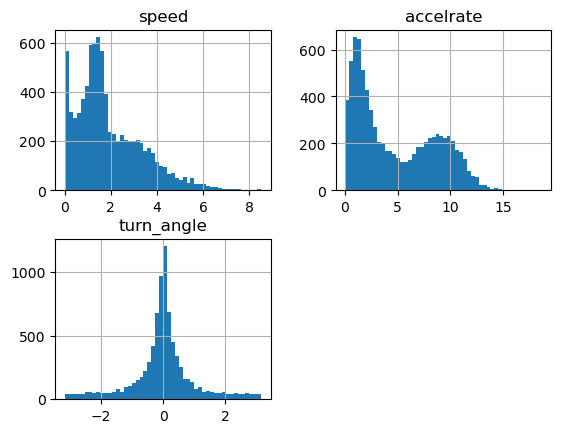

In [58]:
processed_data[["speed", "accelrate", "turn_angle"]].hist(bins=50)

In [2]:
os.chdir("d:/kurssit/Dippatyo/tutkielma/soccer_hmm_project/models/run_37")
os.getcwd()

'd:\\kurssit\\Dippatyo\\tutkielma\\soccer_hmm_project\\models\\run_37'

In [4]:
fit = from_csv("jj")

In [5]:
# print fit adapt delta
print(f"Adapt delta: {fit.metadata['delta']}")

print(fit.metadata)

Adapt delta: 0.95
Metadata:
{'stan_version_major': 2, 'stan_version_minor': 38, 'stan_version_patch': 0, 'model': 'soccer_hmm_2_model', 'start_datetime': '2026-08-18 09:54:57 UTC', 'method': 'sample', 'num_samples': 1000, 'num_warmup': 1000, 'save_warmup': 0, 'thin': 1, 'engaged': 1, 'gamma': 0.05, 'delta': 0.95, 'kappa': 0.75, 't0': 10, 'init_buffer': 75, 'term_buffer': 50, 'window': 25, 'save_metric': 0, 'algorithm': 'hmc', 'engine': 'nuts', 'max_depth': 12, 'metric': 'diag_e', 'metric_file': '', 'stepsize': 1, 'stepsize_jitter': 0, 'num_chains': 4, 'id': 1, 'data_file': 'C:\\Users\\jussi\\AppData\\Local\\Temp\\tmpmbzzze2i\\eshxk9j1.json', 'init': 'C:\\Users\\jussi\\AppData\\Local\\Temp\\tmpmbzzze2i\\dq5qunno.json', 'seed': 67, 'diagnostic_file': '', 'refresh': 100, 'sig_figs': 8, 'profile_file': 'profile.csv', 'save_cmdstan_config': 0, 'num_threads': 4, 'stanc_version': 'stanc3 v2.38.0', 'stancflags': '--filename-in-msg=soccer_hmm_2.stan', 'Step size': 0.182341, 'raw_header': 'lp__,

In [ ]:
a = [1, 2, 3, 4, 5]


In [6]:
print(fit.diagnose())

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
The E-BFMI, 0.00, is below the nominal threshold of 0.30 which suggests that HMC may have trouble exploring the target distribution.
If possible, try to reparameterize the model.

Rank-normalized split effective sample size satisfactory for all parameters.

The following parameters had rank-normalized split R-hat greater than 1.01:
  mu_speeds[1], mu_speeds[2], mu_speeds[3], mu_speeds[4], mu_speeds[5], sigma_speeds[1], sigma_speeds[2], sigma_speeds[3], sigma_speeds[4], sigma_speeds[5], mu_loads[1], mu_loads[2], mu_loads[3], mu_loads[4], mu_loads[5], sigma_loads[1], sigma_loads[2], sigma_loads[3], sigma_loads[4], sigma_loads[5], xangle[1], xangle[2], xangle[3], xangle[4], xangle[5], yangle[1], yangle[2], yangle[3], yangle[4], beta[1,1], beta[2,1], beta[3,1], beta[4,1

In [9]:
fit.summary().head(30)

,Mean,MCSE,StdDev,MAD,5%,50%,95%,ESS_bulk,ESS_tail,ESS_bulk/s,R_hat
lp__,-32798.600000,175.477000,215.295000,48.905000,-33108.600000,-32662.900000,-32624.200000,3.70485,1500.0000,0.000813,2.36970
mu_speeds[1],0.381618,0.210080,0.257963,0.039108,0.175846,0.212482,0.766114,3.77735,1500.0000,0.000829,2.27558
mu_speeds[2],0.834873,0.054866,0.068782,0.090687,0.726290,0.847091,0.923996,3.71678,1500.0000,0.000815,2.36507
mu_speeds[3],1.424610,0.052194,0.065064,0.068470,1.339000,1.405850,1.520560,3.71826,1500.0000,0.000816,2.33422
mu_speeds[4],1.564370,0.030019,0.038657,0.040667,1.505460,1.574970,1.618250,4.09565,1500.0000,0.000898,1.97682
mu_speeds[5],3.502310,0.014268,0.029007,0.030262,3.455790,3.501980,3.550160,9.71045,126.5020,0.002130,1.22323
sigma_speeds[1],0.229309,0.036244,0.045179,0.040115,0.174356,0.212241,0.297835,3.79773,1500.0000,0.000833,2.24006
sigma_speeds[2],0.544810,0.305447,0.375022,0.015151,0.269970,0.284760,1.106670,4.79009,1500.0000,0.001051,1.66393
sigma_speeds[3],0.281974,0.112716,0.138457,0.018446,0.172519,0.190118,0.490517,4.02050,1500.0000,0.000882,2.03564
sigma_speeds[4],0.363136,0.094932,0.116837,0.036294,0.192065,0.434191,0.468298,4.04416,1500.0000,0.000887,2.01231


In [12]:
print(f"Number of sampling draws: {fit.num_draws_sampling}")
print(f"Number of warmup draws: {fit.num_draws_warmup}")
print(f"Number of chains: {fit.chains}")

Number of sampling draws: 1000
Number of warmup draws: 1000
Number of chains: 3


In [10]:
import arviz as az
idata = az.from_cmdstanpy(posterior=fit, log_likelihood="lp__")
posterior_draws = az.extract(idata, combined=True)

In [7]:
import pandas as pd
import numpy as np

np.random.seed(0)

# 10 Hz time index
idx = pd.date_range("2026-01-01 00:00:00", periods=100, freq="100ms")

df = pd.DataFrame(
    {"speed": np.random.uniform(0, 6, size=len(idx))},
    index=idx,
)

df["bin_2s"] = df.index.ceil("2s")

print(df)

                            speed              bin_2s
2026-01-01 00:00:00.000  3.292881 2026-01-01 00:00:00
2026-01-01 00:00:00.100  4.291136 2026-01-01 00:00:02
2026-01-01 00:00:00.200  3.616580 2026-01-01 00:00:02
2026-01-01 00:00:00.300  3.269299 2026-01-01 00:00:02
2026-01-01 00:00:00.400  2.541929 2026-01-01 00:00:02
...                           ...                 ...
2026-01-01 00:00:09.500  1.099148 2026-01-01 00:00:10
2026-01-01 00:00:09.600  3.519078 2026-01-01 00:00:10
2026-01-01 00:00:09.700  0.120645 2026-01-01 00:00:10
2026-01-01 00:00:09.800  4.973640 2026-01-01 00:00:10
2026-01-01 00:00:09.900  0.028173 2026-01-01 00:00:10

[100 rows x 2 columns]


array([[<Axes: title={'center': 'mu_speeds'}>,
        <Axes: title={'center': 'mu_speeds'}>],
       [<Axes: title={'center': 'sigma_speeds'}>,
        <Axes: title={'center': 'sigma_speeds'}>],
       [<Axes: title={'center': 'mu_loads'}>,
        <Axes: title={'center': 'mu_loads'}>],
       [<Axes: title={'center': 'sigma_loads'}>,
        <Axes: title={'center': 'sigma_loads'}>],
       [<Axes: title={'center': 'xangle'}>,
        <Axes: title={'center': 'xangle'}>],
       [<Axes: title={'center': 'yangle'}>,
        <Axes: title={'center': 'yangle'}>]], dtype=object)

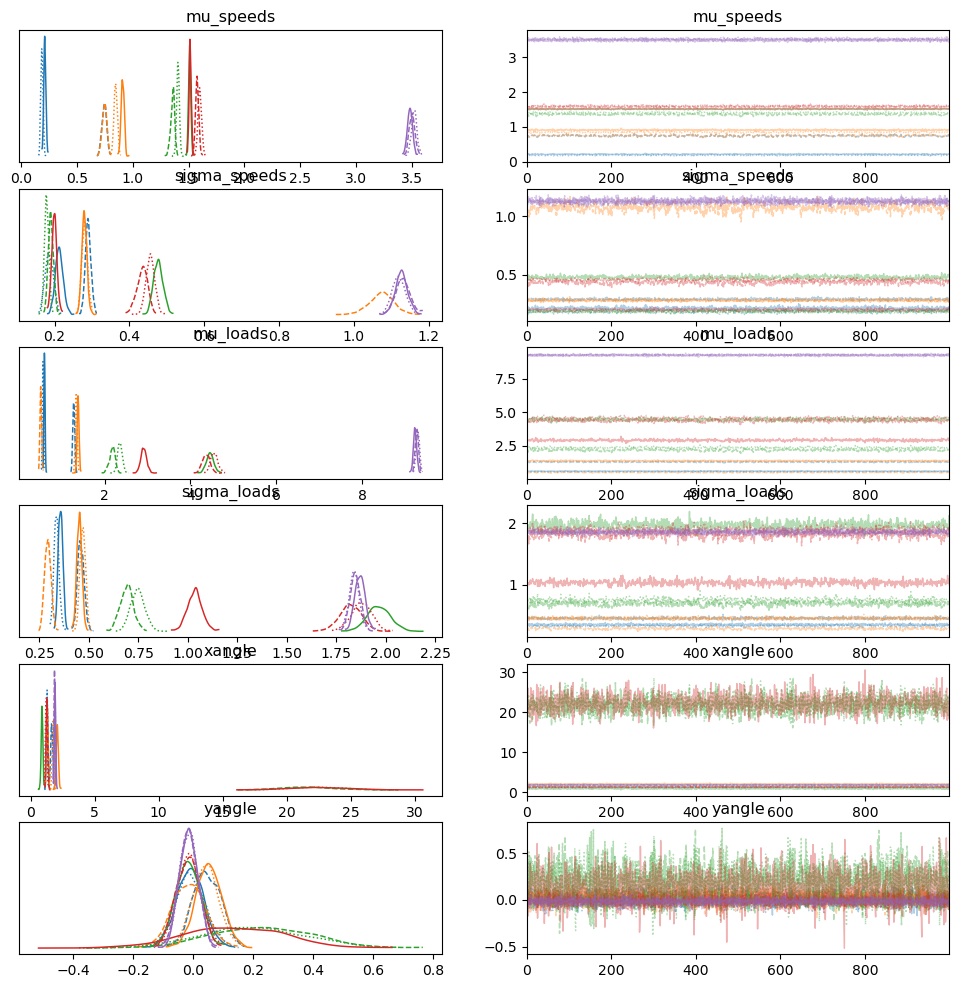

In [11]:
az.plot_trace(idata, var_names=["mu_speeds", "sigma_speeds", "mu_loads", "sigma_loads", "xangle", "yangle"], combined=False)

array([[<Axes: title={'center': 'yangle'}>,
        <Axes: title={'center': 'yangle'}>],
       [<Axes: title={'center': 'loc'}>, <Axes: title={'center': 'loc'}>]],
      dtype=object)

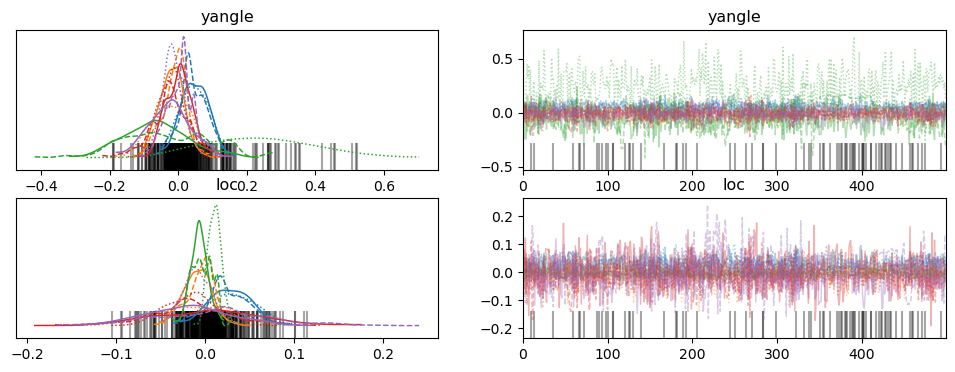

In [8]:
az.plot_trace(idata, var_names=["yangle", "loc"], combined=False)

array([[<Axes: title={'center': 'mu_speeds\n0'}>,
        <Axes: title={'center': 'mu_speeds\n1'}>,
        <Axes: title={'center': 'mu_speeds\n2'}>],
       [<Axes: title={'center': 'mu_speeds\n3'}>,
        <Axes: title={'center': 'mu_speeds\n4'}>,
        <Axes: title={'center': 'sigma_speeds\n0'}>],
       [<Axes: title={'center': 'sigma_speeds\n1'}>,
        <Axes: title={'center': 'sigma_speeds\n2'}>,
        <Axes: title={'center': 'sigma_speeds\n3'}>],
       [<Axes: title={'center': 'sigma_speeds\n4'}>,
        <Axes: title={'center': 'mu_loads\n0'}>,
        <Axes: title={'center': 'mu_loads\n1'}>],
       [<Axes: title={'center': 'mu_loads\n2'}>,
        <Axes: title={'center': 'mu_loads\n3'}>,
        <Axes: title={'center': 'mu_loads\n4'}>],
       [<Axes: title={'center': 'sigma_loads\n0'}>,
        <Axes: title={'center': 'sigma_loads\n1'}>,
        <Axes: title={'center': 'sigma_loads\n2'}>],
       [<Axes: title={'center': 'sigma_loads\n3'}>,
        <Axes: title={'cen

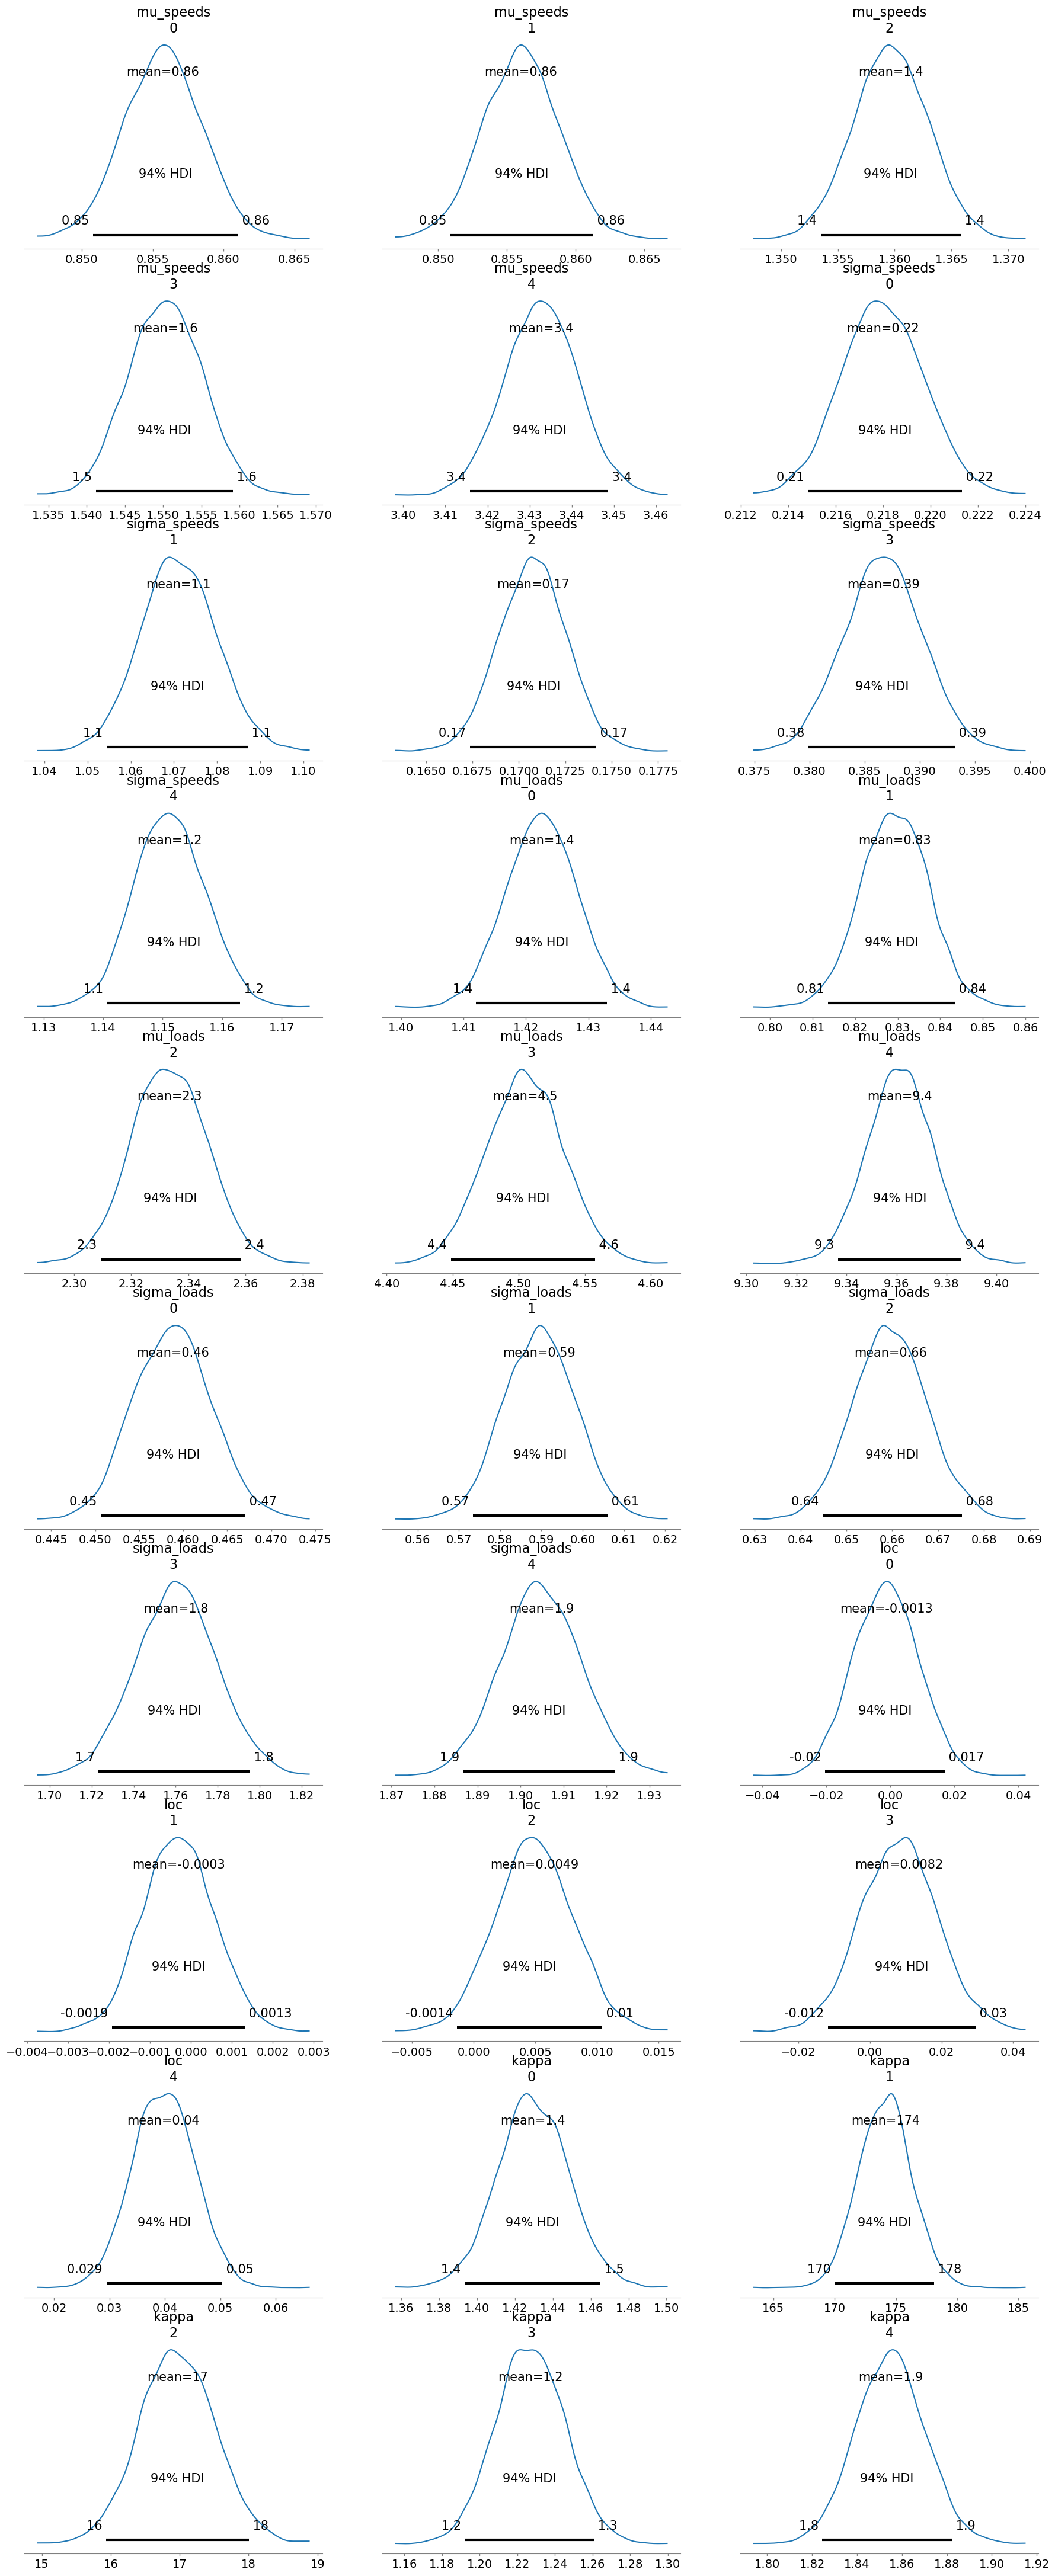

In [44]:
az.plot_posterior(idata, var_names=["mu_speeds", "sigma_speeds", "mu_loads", "sigma_loads", "loc", "kappa"])

In [19]:
import numpy as np

idx = np.random.choice(np.arange(100), size=5)
print(idx)
a = np.arange(100)*3
print(a[idx])

[36  6 71 54 16]
[108  18 213 162  48]


In [20]:
posterior_draws["kappa"].mean(axis=1)

<xarray.DataArray 'kappa' (chain: 7, kappa_dim_0: 5)> Size: 280B
array([[ 1.42730869, 23.99518755, 14.95489505,  1.72503015,  2.01407436],
       [17.39404464,  1.70778341,  1.72566217,  0.90456279, 14.41741663],
       [17.36777404,  1.70054846,  1.73511722,  0.90045773, 14.41030469],
       [17.32362973,  1.69510509,  1.73168146,  0.90827375, 14.4392973 ],
       [17.39056138,  1.70283198,  1.73075359,  0.90497821, 14.49898758],
       [17.41596147,  1.7021983 ,  1.72722394,  0.90656965, 14.51993896],
       [17.37304191,  1.70042284,  1.73014711,  0.90724824, 14.50736957]])
Coordinates:
  * chain        (chain) int64 56B 0 1 2 3 4 5 6
  * kappa_dim_0  (kappa_dim_0) int64 40B 0 1 2 3 4

array([[<Axes: title={'center': 'beta'}>,
        <Axes: title={'center': 'beta'}>]], dtype=object)

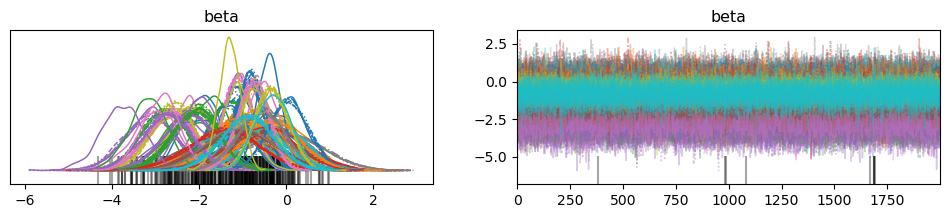

In [21]:
az.plot_trace(idata, var_names=["beta"])

In [22]:
from src.modeling.model_checks import compute_all_pseudo_residuals
from src.modeling.inference import build_transition_matrix

In [23]:
posterior_draws["xangle"].std(axis=1)

<xarray.DataArray 'xangle' (chain: 7, xangle_dim_0: 5)> Size: 280B
array([[0.14328149, 2.42595439, 2.03598328, 0.15234654, 0.12616805],
       [1.71021634, 0.16651713, 0.14430479, 0.17261051, 1.97596777],
       [1.8624645 , 0.16417062, 0.14333367, 0.17196376, 2.01092403],
       [1.86843767, 0.17168948, 0.14294536, 0.15925566, 1.92362478],
       [1.86488426, 0.15922371, 0.14528528, 0.16579089, 1.97927478],
       [1.79035493, 0.16040799, 0.14210922, 0.16535963, 2.02803895],
       [1.83867482, 0.16480916, 0.1386186 , 0.17017021, 1.99245502]])
Coordinates:
  * chain         (chain) int64 56B 0 1 2 3 4 5 6
  * xangle_dim_0  (xangle_dim_0) int64 40B 0 1 2 3 4

In [24]:
posterior_draws["yangle"].mean(axis=1)

<xarray.DataArray 'yangle' (chain: 7, yangle_dim_0: 5)> Size: 280B
array([[-0.06874428,  0.02083496,  0.07316821,  0.17265741,  0.04139705],
       [-0.39574181, -0.03288883,  0.17464237,  0.12606041, -0.41560572],
       [-0.40592462, -0.03167349,  0.17459405,  0.12353326, -0.40985799],
       [-0.39276348, -0.0331933 ,  0.17397959,  0.12508028, -0.41366097],
       [-0.39835051, -0.0339261 ,  0.17585794,  0.12346566, -0.40665281],
       [-0.40941726, -0.03720734,  0.17666802,  0.12259695, -0.40919605],
       [-0.39138991, -0.03241582,  0.1736333 ,  0.1266897 , -0.42156889]])
Coordinates:
  * chain         (chain) int64 56B 0 1 2 3 4 5 6
  * yangle_dim_0  (yangle_dim_0) int64 40B 0 1 2 3 4

In [25]:
loo_orig = az.loo(idata, pointwise=True)
loo_orig

c:\Anaconda\envs\soccer_hmm\Lib\site-packages\arviz\stats\stats.py:1042: RuntimeWarning: overflow encountered in exp
  weights = 1 / np.exp(len_scale - len_scale[:, None]).sum(axis=1)
c:\Anaconda\envs\soccer_hmm\Lib\site-packages\arviz\stats\stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
c:\Anaconda\envs\soccer_hmm\Lib\site-packages\arviz\stats\stats.py:825: UserWarning: The point-wise LOO is the same with the sum LOO, please double check the Observed RV in your model to make sure it returns element-wise logp.
  warnings.warn(


Computed from 14000 posterior samples and 1.0 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -5160.54     0.00
p_loo      278.52        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)        0    0.0%
   (0.70, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    1  100.0%

In [3]:
processed = pd.read_csv(processed_data_file, parse_dates=["timestamp"])

In [4]:
processed[processed["player_id"] == 18].groupby(["track_id", "segment_id"]).agg({"timestamp": ["min", "max"]})

timestamp                    
                                    min                 max
track_id segment_id                                        
24       0          2025-07-01 20:01:04 2025-07-01 20:47:24
         1          2025-07-01 20:59:14 2025-07-01 21:48:12
33       0          2025-06-11 20:00:48 2025-06-11 20:46:16
         1          2025-06-11 20:59:26 2025-06-11 21:43:00
38       0          2025-05-16 20:01:00 2025-05-16 20:45:46
         1          2025-05-16 21:00:28 2025-05-16 21:47:06

In [8]:
processed = processed[processed["player_id"] == 18]

In [15]:
import numpy as np

In [16]:
# Check for gaps in the data
dt = processed["timestamp"].diff()
gaps = dt[np.abs(dt) > pd.Timedelta(seconds=2)]
gaps

54860      0 days 00:11:50
76916   -21 days +22:12:36
78281      0 days 00:13:10
89603   -27 days +22:18:00
90947      0 days 00:14:42
Name: timestamp, dtype: timedelta64[ns]

In [19]:
# segment lengths
segment_lengths = processed.groupby(["track_id", "segment_id"]).agg({"timestamp": ["min", "max"]})
segment_lengths["segment_length"] = segment_lengths["timestamp"]["max"] - segment_lengths["timestamp"]["min"]
segment_lengths["segment_length"]

track_id  segment_id
24        0            0 days 00:46:20
          1            0 days 00:48:58
33        0            0 days 00:45:28
          1            0 days 00:43:34
38        0            0 days 00:44:46
          1            0 days 00:46:38
Name: segment_length, dtype: timedelta64[ns]

In [10]:
dt

53469               NaT
53470   0 days 00:00:02
53471   0 days 00:00:02
53472   0 days 00:00:02
53473   0 days 00:00:02
              ...      
92342   0 days 00:00:02
92343   0 days 00:00:02
92344   0 days 00:00:02
92345   0 days 00:00:02
92346   0 days 00:00:02
Name: timestamp, Length: 8278, dtype: timedelta64[ns]

In [11]:
processed[processed["player_id"] == 18]["accelrate"].describe()

count    8278.000000
mean        4.866622
std         3.787512
min         0.036224
25%         1.434140
50%         3.663792
75%         8.321298
max        18.634503
Name: accelrate, dtype: float64

In [9]:
processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100240 entries, 0 to 100239
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   timestamp                    100240 non-null  datetime64[ns]
 1   x                            100240 non-null  float64       
 2   y                            100240 non-null  float64       
 3   speed                        100240 non-null  float64       
 4   playerload                   100240 non-null  float64       
 5   accelrate                    100240 non-null  float64       
 6   track_id                     100240 non-null  int64         
 7   game                         100240 non-null  int64         
 8   position                     100240 non-null  object        
 9   player                       100240 non-null  object        
 10  turn_angle                   100240 non-null  float64       
 11  is_valid                  

In [ ]:
processed[["timestamp", "accelrate", "accelrate_cumulative_10s"]].head(20)

,timestamp,accelrate,accelrate_cumulative_10s
0,2025-08-20 20:05:42,8.316806,0.000000
1,2025-08-20 20:05:44,6.456971,8.316806
2,2025-08-20 20:05:46,6.893636,14.773777
3,2025-08-20 20:05:48,13.309773,21.667413
4,2025-08-20 20:05:50,11.625488,34.977185
5,2025-08-20 20:05:52,11.601833,46.602673
6,2025-08-20 20:05:54,9.527457,49.887700
7,2025-08-20 20:05:56,10.034819,52.958187
8,2025-08-20 20:05:58,3.700693,56.099370
9,2025-08-20 20:06:00,2.713060,46.490290


In [5]:
processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100240 entries, 0 to 100239
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   timestamp                    100240 non-null  datetime64[ns]
 1   x                            100240 non-null  float64       
 2   y                            100240 non-null  float64       
 3   speed                        100240 non-null  float64       
 4   playerload                   100240 non-null  float64       
 5   accelrate                    100240 non-null  float64       
 6   track_id                     100240 non-null  int64         
 7   game                         100240 non-null  int64         
 8   position                     100240 non-null  object        
 9   player                       100240 non-null  object        
 10  turn_angle                   100240 non-null  float64       
 11  is_valid                  

In [9]:
#Based on timestamp, find the first over 10 second gap

time_diffs = processed["timestamp"].diff().dt.total_seconds()
time_gaps = time_diffs[time_diffs > 10]

processed[2634:2644+10][["track_id","timestamp", "accelrate", "accelrate_cumulative_10s"]]


,track_id,timestamp,accelrate,accelrate_cumulative_10s
2634,1,2025-08-20 20:47:20,6.787656,35.798409
2635,1,2025-08-20 20:47:22,9.014143,35.079077
2636,1,2025-08-20 20:47:24,6.737529,33.696770
2637,1,2025-08-20 20:47:26,1.593047,32.963504
2638,1,2025-08-20 20:47:28,4.527660,27.283683
2639,1,2025-08-20 20:47:30,9.050830,28.660036
2640,1,2025-08-20 20:47:32,6.692766,30.923209
2641,1,2025-08-20 20:47:34,11.364878,28.601832
2642,1,2025-08-20 20:47:36,6.762527,33.229182
2643,1,2025-08-20 20:47:38,4.561124,38.398662


In [10]:
time_gaps

2644        724.0
5479        618.0
8203         30.0
8217        600.0
10943       542.0
10988        14.0
13670       876.0
16905       718.0
17979    680300.0
19291      1142.0
20986       994.0
23530      1010.0
26057      1044.0
28673       978.0
31651       818.0
31942       348.0
33670       908.0
36494       774.0
39256       786.0
42358       972.0
45155       786.0
47970       470.0
50878       714.0
53067       474.0
55981       710.0
58840       660.0
60910       584.0
63827        48.0
63953        14.0
66786       742.0
69547       728.0
71493       794.0
74214       664.0
77081       612.0
79878       790.0
82592       602.0
85338       788.0
88140       782.0
89951       792.0
92557       882.0
95241       790.0
98011       778.0
99767       884.0
Name: timestamp, dtype: float64

In [12]:
processed[5469:5489+10][["track_id","timestamp", "accelrate", "accelrate_cumulative_10s"]]

,track_id,timestamp,accelrate,accelrate_cumulative_10s
5469,2,2025-08-20 20:48:56,1.392763,9.653629
5470,2,2025-08-20 20:48:58,1.125438,7.880598
5471,2,2025-08-20 20:49:00,1.640187,7.273292
5472,2,2025-08-20 20:49:02,0.453213,7.317345
5473,2,2025-08-20 20:49:04,0.228950,5.890990
5474,2,2025-08-20 20:49:06,0.150498,4.840551
5475,2,2025-08-20 20:49:08,0.272529,3.598286
5476,2,2025-08-20 20:49:10,0.229909,2.745377
5477,2,2025-08-20 20:49:12,0.463866,1.335099
5478,2,2025-08-20 20:49:14,0.976976,1.345752


In [5]:
import numpy as np

In [11]:
processed = processed[processed["player_id"] == 18]

<Axes: >

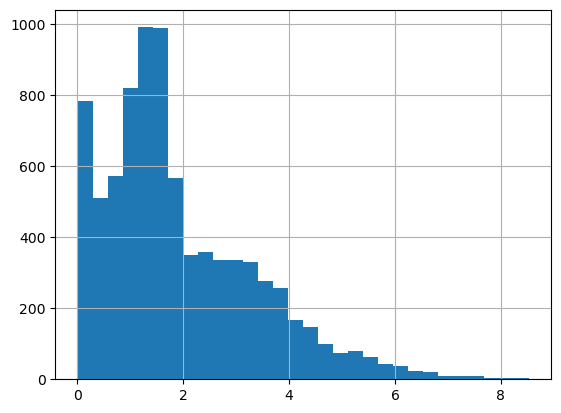

In [13]:
processed["speed"].hist(bins=30)

In [17]:
import numpy as np

In [18]:
2*np.pi/3

2.0943951023931953

<Axes: >

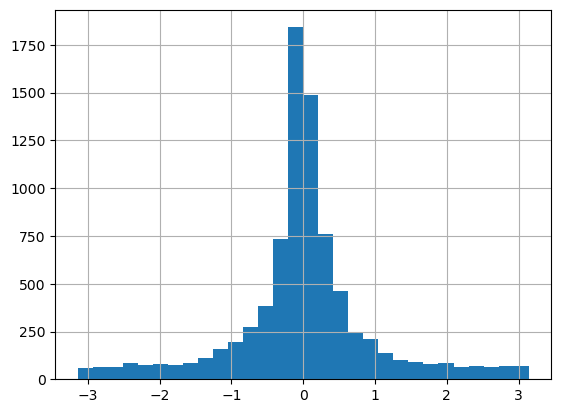

In [15]:
processed["turn_angle"].hist(bins=30)

<Axes: >

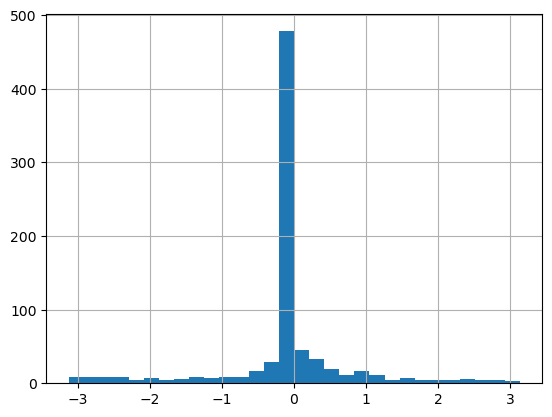

In [22]:
processed[processed["speed"] < 0.3]["turn_angle"].hist(bins=30)

In [29]:
#rename position column values to english
processed["position"] = processed["position"].replace({"hyökkääjä": "forward",
                                                       "keskikenttä": "midfielder",
                                                       "laitapakki": "full-back",
                                                       "toppari": "center-back",
                                                       "linkki": "winger",
                                                       "Linkki": "winger"})
                                                       

In [30]:
processed[processed["position"] == "midfielder"]

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,...,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones,player_id,position_id
4048,2025-08-20 20:01:34,-17.423142,16.331602,4.027477,1.141776,8.570462,2,1,midfielder,SS,...,True,2,1431,0.000621,0.000000,0.000585,0.000000,1,2,1
4049,2025-08-20 20:01:36,-13.598319,14.854199,4.595592,1.193474,8.860274,2,1,midfielder,SS,...,True,2,1431,0.001270,0.000621,0.001190,0.000585,1,2,1
4050,2025-08-20 20:01:38,-10.425820,19.416205,4.252367,1.246454,8.361762,2,1,midfielder,SS,...,True,2,1431,0.001948,0.001270,0.001761,0.001190,1,2,1
4051,2025-08-20 20:01:40,-10.896101,26.978828,4.296145,1.296209,10.267801,2,1,midfielder,SS,...,True,2,1431,0.002653,0.001948,0.002461,0.001761,1,2,1
4052,2025-08-20 20:01:42,-14.220303,32.002762,4.535925,1.251131,8.832309,2,1,midfielder,SS,...,True,2,1431,0.003334,0.002653,0.003064,0.002461,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88655,2025-05-16 21:16:00,10.335140,22.676417,4.302257,1.251079,11.273810,36,6,midfielder,LT,...,True,4,518,0.996981,0.996014,0.997021,0.996034,1,8,1
88656,2025-05-16 21:16:02,6.583460,28.654746,5.240931,1.032267,9.344205,36,6,midfielder,LT,...,True,4,518,0.997780,0.996981,0.997838,0.997021,1,8,1
88657,2025-05-16 21:16:04,3.590461,36.415883,4.941484,0.856389,7.403804,36,6,midfielder,LT,...,True,4,518,0.998442,0.997780,0.998486,0.997838,1,8,1
88658,2025-05-16 21:16:06,1.266998,44.367899,4.670148,1.021036,9.094372,36,6,midfielder,LT,...,True,4,518,0.999232,0.998442,0.999282,0.998486,1,8,1


In [10]:
processed.groupby(["player_id","game","position"]).count()

x     y  speed  playerload  accelrate  \
player_id game position                                                
0         1    forward      1263  1263   1263        1263       1263   
1         1    forward      2787  2787   2787        2787       2787   
2         1    midfielder   2760  2760   2760        2760       2760   
          2    forward      1695  1695   1695        1695       1695   
          3    midfielder   2849  2849   2849        2849       2849   
3         1    midfielder   2839  2839   2839        2839       2839   
4         1    full-back    2770  2770   2770        2770       2770   
          4    full-back    2923  2923   2923        2923       2923   
          6    center-back  1757  1757   1757        1757       1757   
5         1    winger       2426  2426   2426        2426       2426   
6         1    winger        877   877    877         877        877   
          6    winger       1788  1788   1788        1788       1788   
7         1    center-back  2257  2257   2257        2257       2257   
          4    center-back  2687  2687   2687        2687       2687   
8         2    midfielder   2561  2561   2561        2561       2561   
          6    midfielder   1866  1866   1866        1866       1866   
9         2    full-back    2583  2583   2583        2583       2583   
          4    midfielder   2103  2103   2103        2103       2103   
          5    midfielder   2694  2694   2694        2694       2694   
10        2    full-back    2527  2527   2527        2527       2527   
          3    winger       2714  2714   2714        2714       2714   
          4    winger       2788  2788   2788        2788       2788   
          6    winger       2738  2738   2738        2738       2738   
11        2    winger       2040  2040   2040        2040       2040   
          3    winger        922   922    922         922        922   
          5    winger       2836  2836   2836        2836       2836   
12        2    winger        882   882    882         882        882   
13        3    forward      2105  2105   2105        2105       2105   
          5    forward      2007  2007   2007        2007       2007   
          6    forward      2770  2770   2770        2770       2770   
14        3    midfielder   2718  2718   2718        2718       2718   
15        3    full-back    2228  2228   2228        2228       2228   
16        3    center-back  2797  2797   2797        2797       2797   
          4    center-back  3018  3018   3018        3018       3018   
17        4    forward      2964  2964   2964        2964       2964   
18        4    full-back    2861  2861   2861        2861       2861   
          5    full-back    2673  2673   2673        2673       2673   
          6    full-back    2744  2744   2744        2744       2744   
19        4    winger       2177  2177   2177        2177       2177   
20        5    midfielder   2859  2859   2859        2859       2859   
21        5    full-back    2832  2832   2832        2832       2832   
22        6    full-back    2555  2555   2555        2555       2555   

                            track_id  player  turn_angle  is_valid  \
player_id game position                                              
0         1    forward          1263    1263        1263      1263   
1         1    forward          2787    2787        2787      2787   
2         1    midfielder       2760    2760        2760      2760   
          2    forward          1695    1695        1695      1695   
          3    midfielder       2849    2849        2849      2849   
3         1    midfielder       2839    2839        2839      2839   
4         1    full-back        2770    2770        2770      2770   
          4    full-back        2923    2923        2923      2923   
          6    center-back      1757    1757        1757      1757   
5         1    winger           2426    2426        2426      2426   
6         1    winger 

In [26]:
processed[processed["player_id"] == 14]["position"].unique()

array(['full-back'], dtype=object)

In [1]:
processed["player_id"].unique()

NameError: name 'processed' is not defined

In [27]:
processed[processed["position"] == "full-back"]

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,...,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones,player_id,position_id
11984,2025-08-28 18:35:42,-1.157653,3.328929,4.079588,1.379142,11.883100,5,2,full-back,EP,...,True,2,1295,0.000912,0.000000,0.000903,0.000000,1,5,3
11985,2025-08-28 18:35:44,-5.622067,8.936952,5.683934,1.286410,8.858612,5,2,full-back,EP,...,True,2,1295,0.001763,0.000912,0.001577,0.000903,1,5,3
11986,2025-08-28 18:35:46,-9.087384,14.861834,4.141144,1.325101,11.081947,5,2,full-back,EP,...,True,2,1295,0.002640,0.001763,0.002419,0.001577,1,5,3
11987,2025-08-28 18:35:48,-10.193458,20.973777,2.768355,1.207876,9.049505,5,2,full-back,EP,...,True,2,1295,0.003439,0.002640,0.003107,0.002419,1,5,3
11988,2025-08-28 18:35:50,-10.430338,25.035681,1.771459,1.456610,11.674275,5,2,full-back,EP,...,True,2,1295,0.004403,0.003439,0.003995,0.003107,1,5,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97676,2025-05-16 21:46:54,-19.001040,16.812616,2.683688,1.249588,11.250401,40,6,full-back,OK,...,True,4,1400,0.996322,0.995443,0.996700,0.995791,1,14,3
97677,2025-05-16 21:46:56,-18.854995,16.301061,2.732466,1.495098,10.531295,40,6,full-back,OK,...,True,4,1400,0.997374,0.996322,0.997550,0.996700,1,14,3
97678,2025-05-16 21:46:58,-17.800435,24.493585,5.956492,1.258384,11.316643,40,6,full-back,OK,...,True,4,1400,0.998260,0.997374,0.998465,0.997550,1,14,3
97679,2025-05-16 21:47:00,-18.625495,35.178987,5.083152,1.281016,8.613434,40,6,full-back,OK,...,True,4,1400,0.999161,0.998260,0.999161,0.998465,1,14,3


<Axes: >

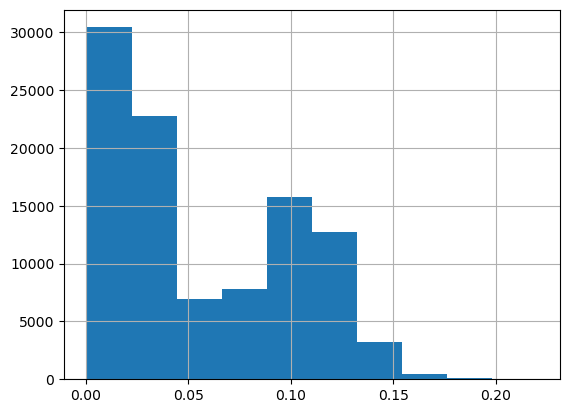

In [ ]:
(processed["playerload"]/10).hist()

In [ ]:
(processed["playerload"]/10).sum()

np.float64(5762.304280839149)

In [ ]:
processed.head()

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,...,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones,player_id,position_id
0,2025-08-20 20:05:38,-10.205863,5.619476,3.087025,1.428486,12.793343,0,1,hyökkääjä,JM,...,True,2,1263,0.001908,0.000000,0.001895,0.000000,1,0,0
1,2025-08-20 20:05:40,-10.228619,3.298388,2.275129,1.138060,11.409284,0,1,hyökkääjä,JM,...,True,2,1263,0.003428,0.001908,0.003584,0.001895,1,0,0
2,2025-08-20 20:05:42,-9.900560,8.585734,4.320701,1.382315,8.316806,0,1,hyökkääjä,JM,...,True,2,1263,0.005274,0.003428,0.004816,0.003584,1,0,0
3,2025-08-20 20:05:44,-6.162961,17.591403,7.440726,1.125531,6.456971,0,1,hyökkääjä,JM,...,True,2,1263,0.006777,0.005274,0.005772,0.004816,1,0,0
4,2025-08-20 20:05:46,-0.341333,28.467684,8.421956,1.080297,6.893636,0,1,hyökkääjä,JM,...,True,2,1263,0.008220,0.006777,0.006793,0.005772,1,0,0


In [ ]:
processed.groupby("track_id")["playerload"].sum()/10

track_id
0      74.871592
1     155.094632
2     183.859570
3     189.064229
4     199.375014
5     138.428479
6      52.051391
7     131.424044
8      76.673064
9     153.545794
10    151.153081
11    132.966996
12    125.100140
13     48.259172
14     97.700838
15    163.604114
16    193.754723
17    110.421905
18     51.725603
19    164.767745
20    126.548520
21    159.280764
22    138.325904
23    196.666131
24    168.827240
25    113.724664
26    145.439692
27    123.542587
28    151.439388
29     86.319642
30    184.713849
31    168.988805
32    143.926155
33    148.165594
34    175.259358
35    118.271545
36    129.315912
37    162.479982
38    142.121426
39    167.565230
40     98.343288
41    119.196481
Name: playerload, dtype: float64

In [ ]:
processed["playerload"].describe()

count    100242.000000
mean          0.574839
std           0.433550
min           0.003823
25%           0.195025
50%           0.387080
75%           0.998745
max           2.202469
Name: playerload, dtype: float64

In [ ]:
processed["playerload"].describe()

count    100242.000000
mean          0.574839
std           0.433550
min           0.003823
25%           0.195025
50%           0.387080
75%           0.998745
max           2.202469
Name: playerload, dtype: float64

In [ ]:
processed["player"].unique()

array(['JM', 'NN', 'SS', 'ST', 'AA', 'JN', 'RM', 'NR', 'LT', 'EP', 'OG',
       'EB', 'ET', 'OH', 'BP', 'OS', 'ML', 'KL', 'OK', 'AY', 'PB', 'OKe',
       'OKes'], dtype=object)

In [ ]:
processed["player_id"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22])

In [ ]:
processed["track_id"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41])

In [ ]:
processed.se

(100282, 21)

c:\Anaconda\envs\soccer_hmm\Lib\site-packages\pandas\plotting\_matplotlib\core.py:580: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = self.plt.figure(figsize=self.figsize)


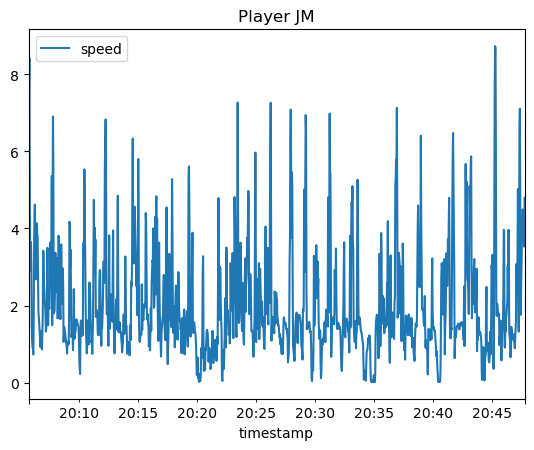

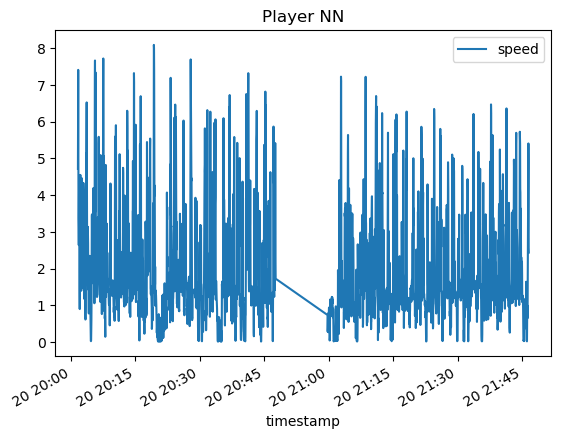

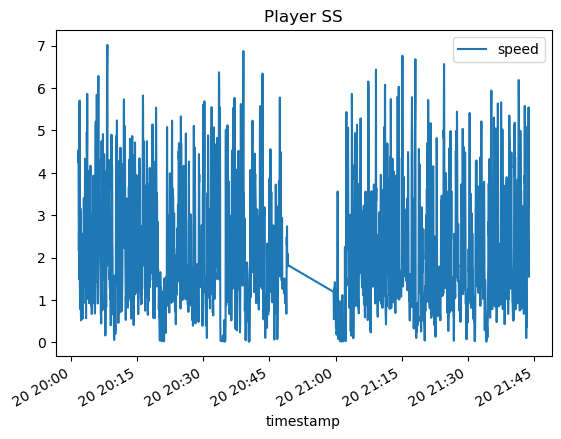

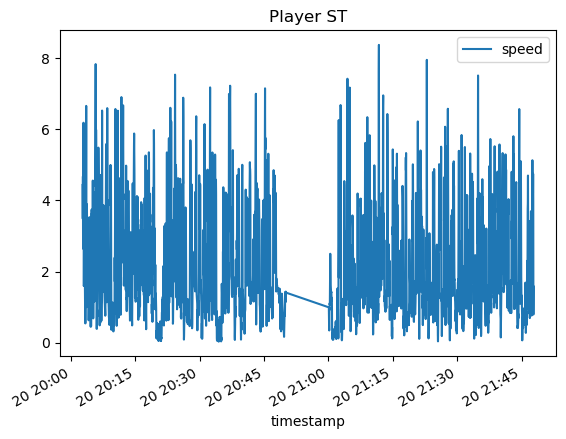

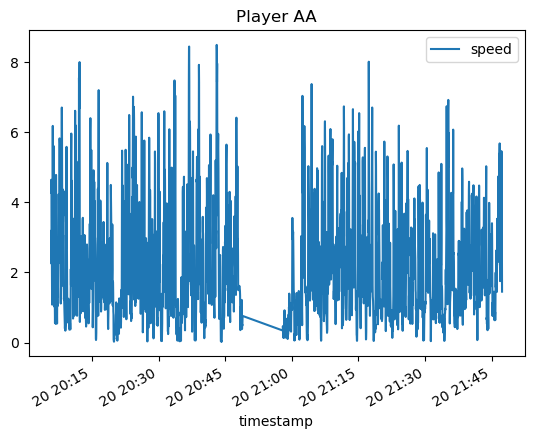

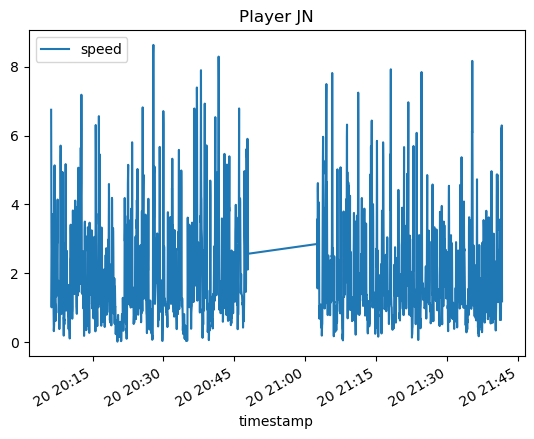

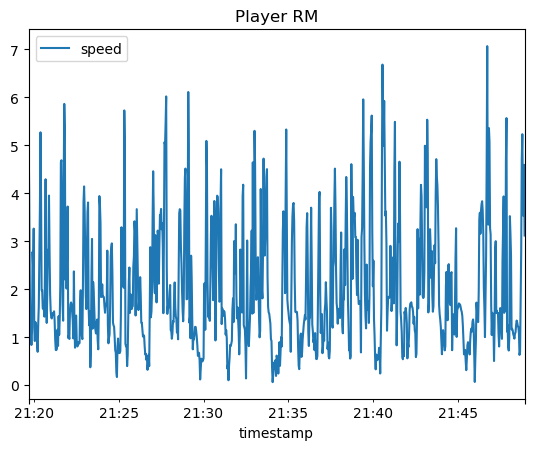

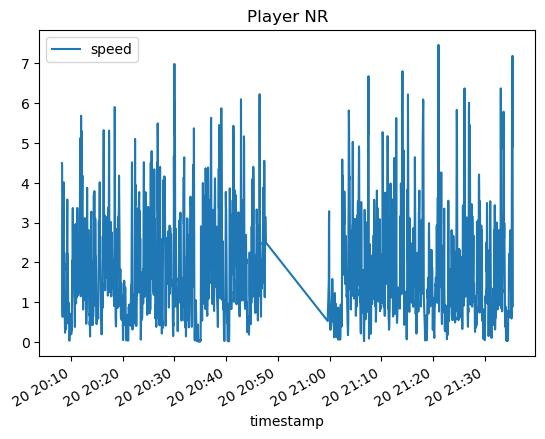

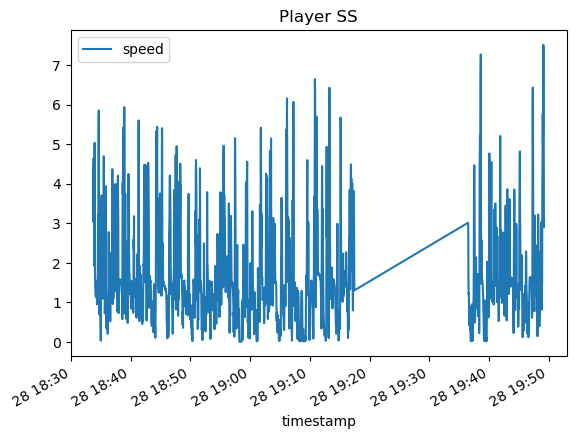

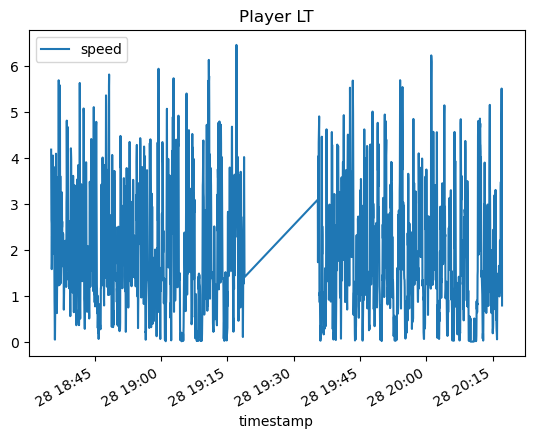

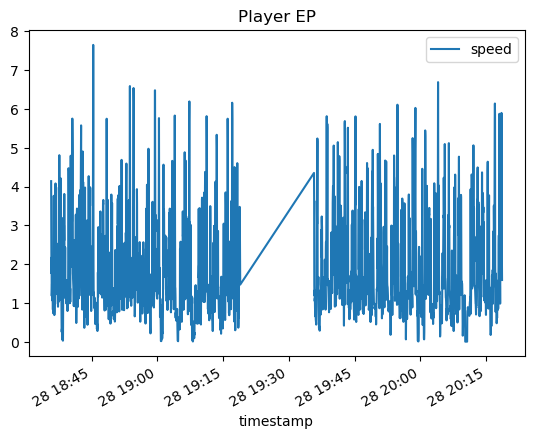

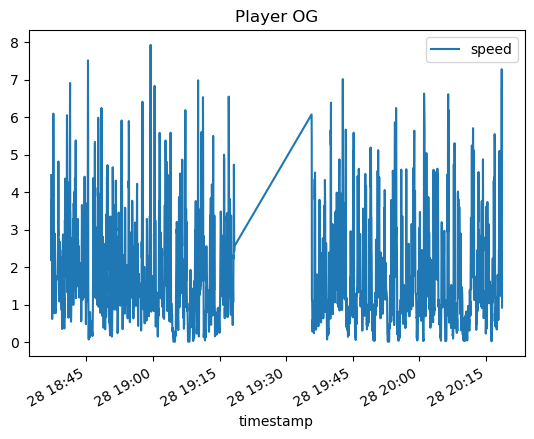

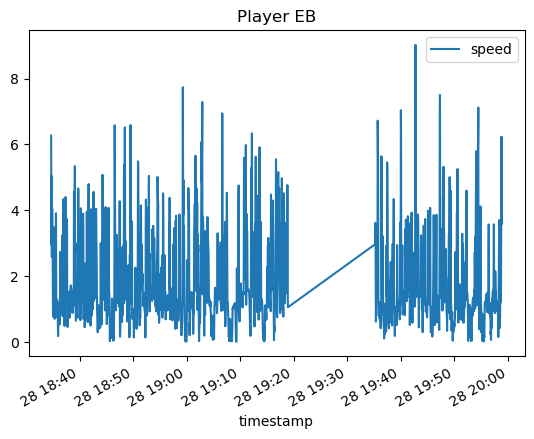

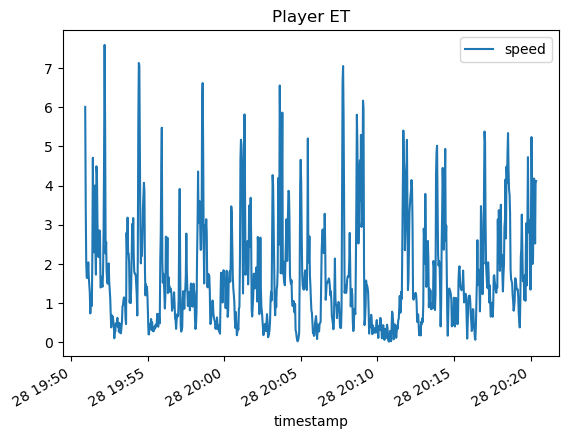

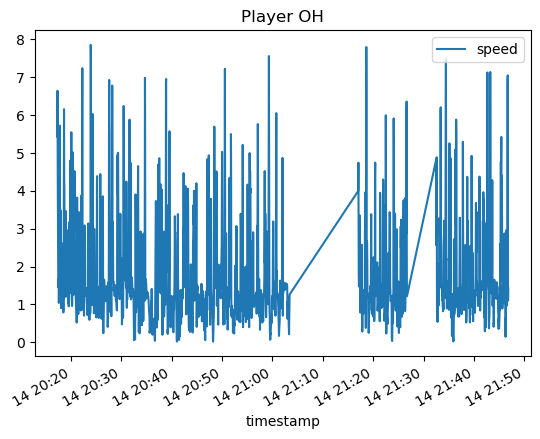

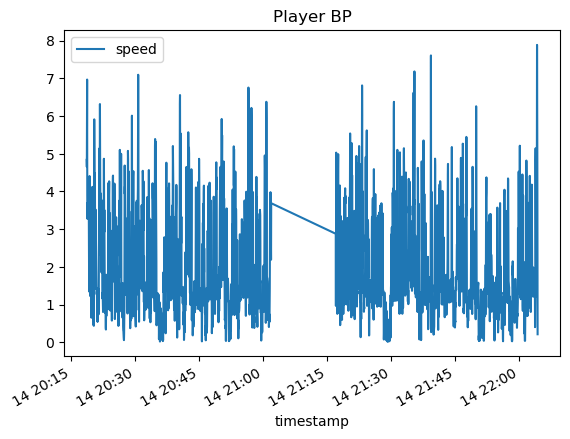

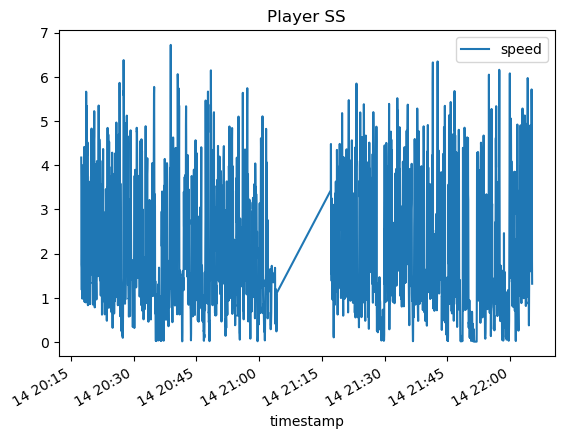

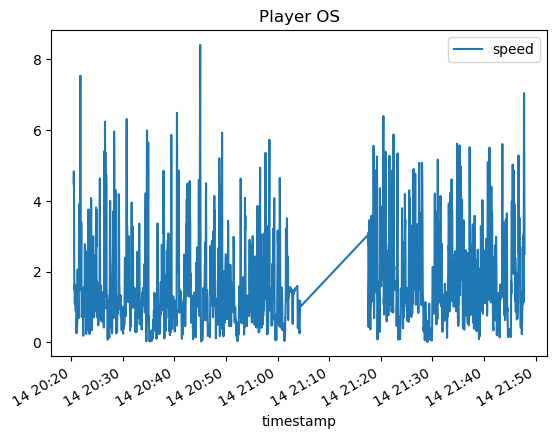

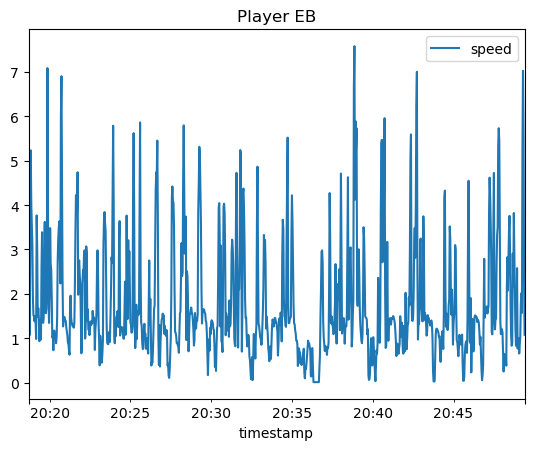

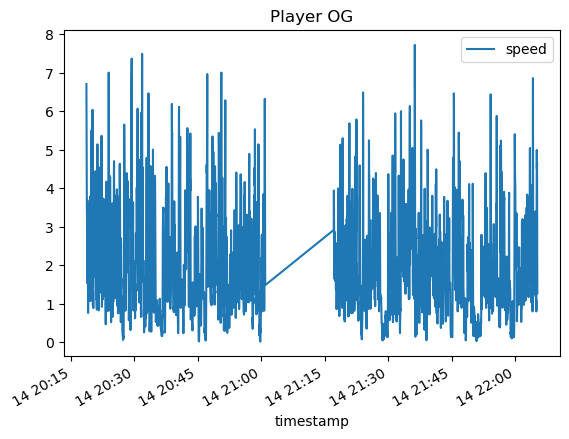

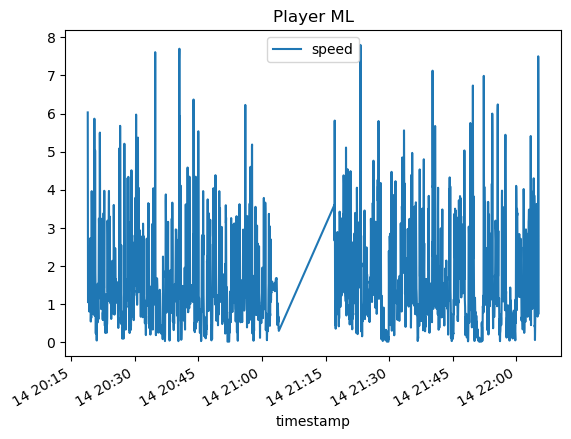

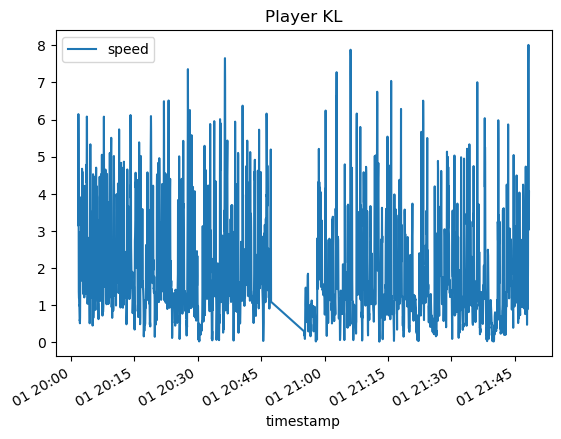

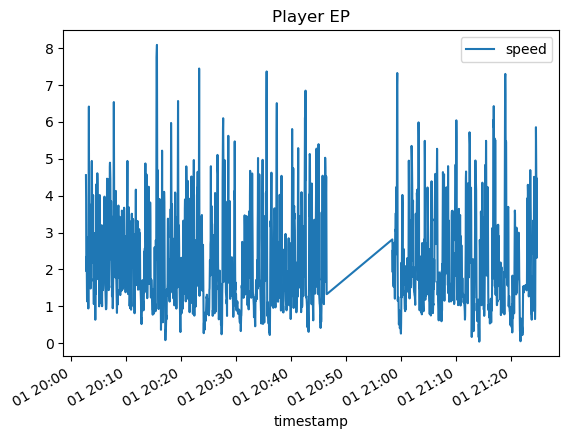

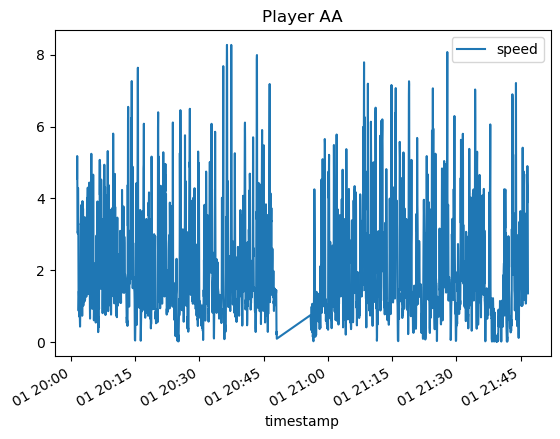

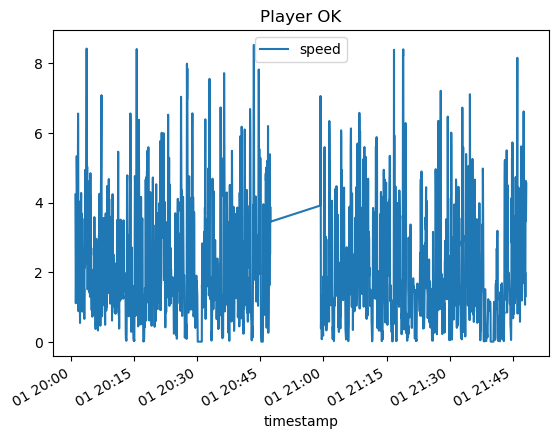

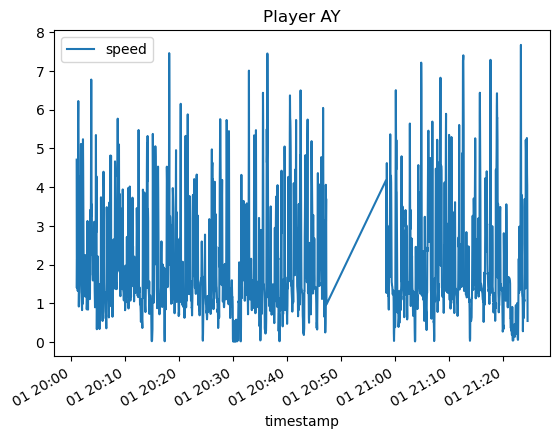

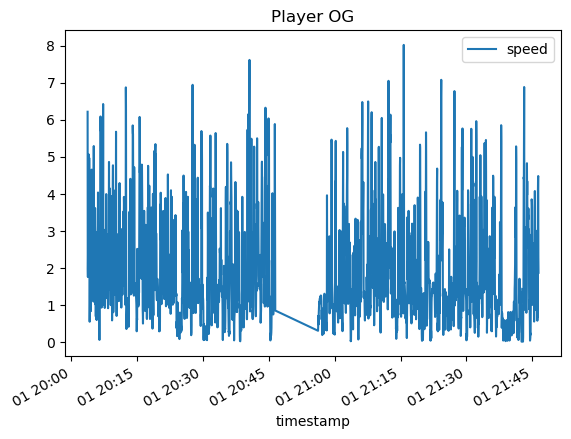

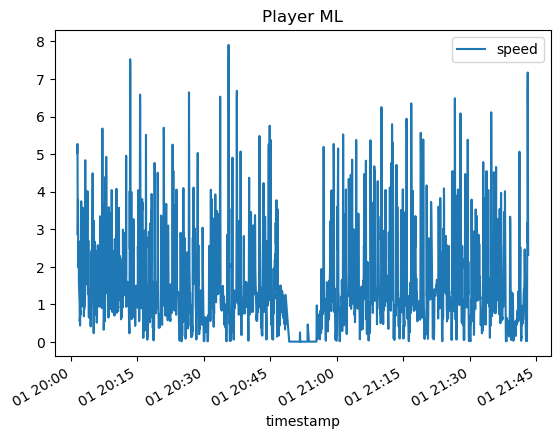

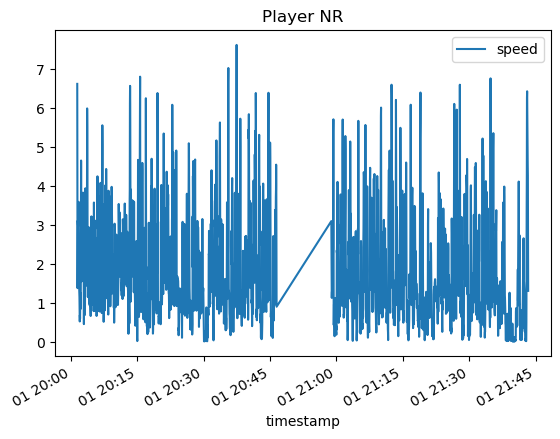

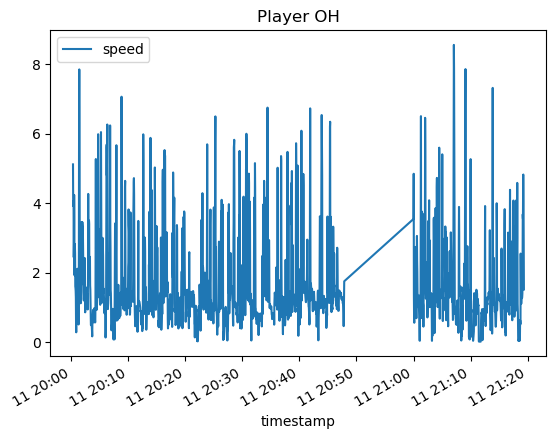

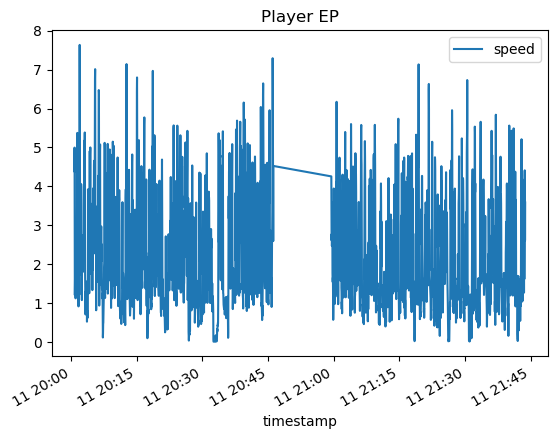

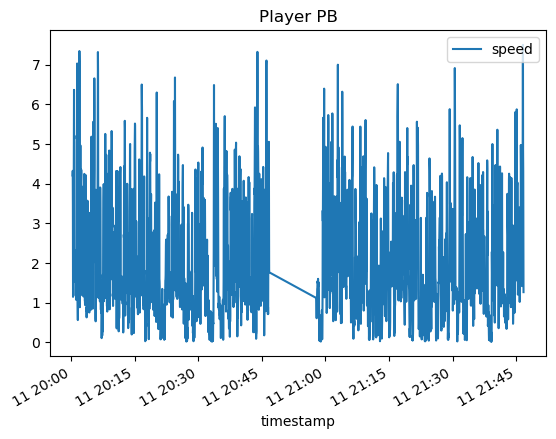

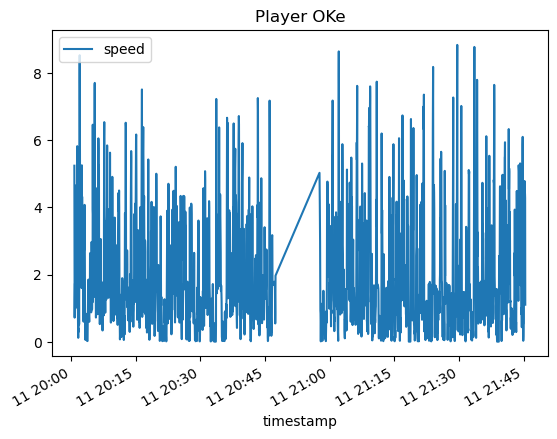

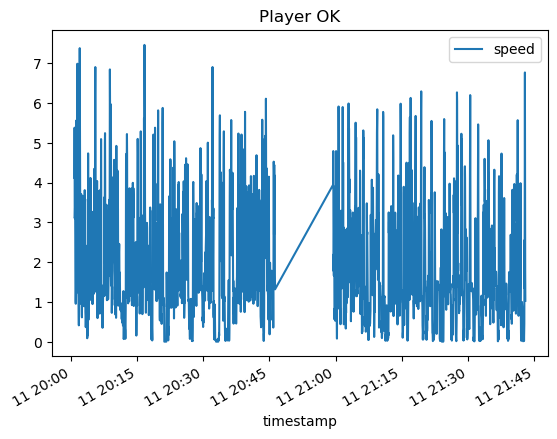

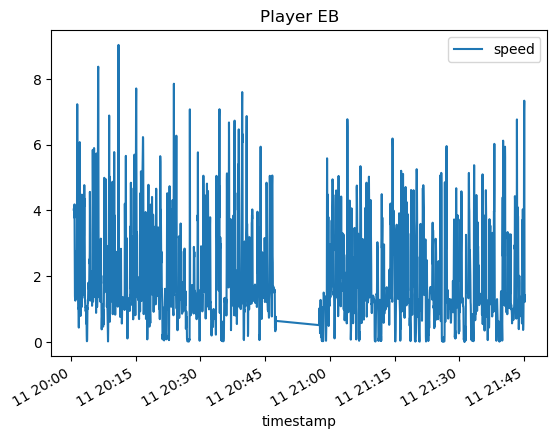

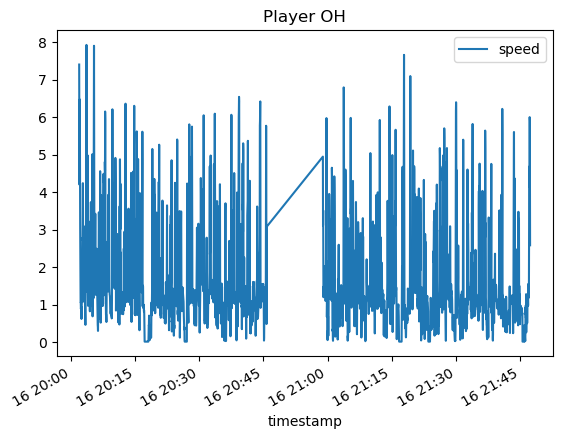

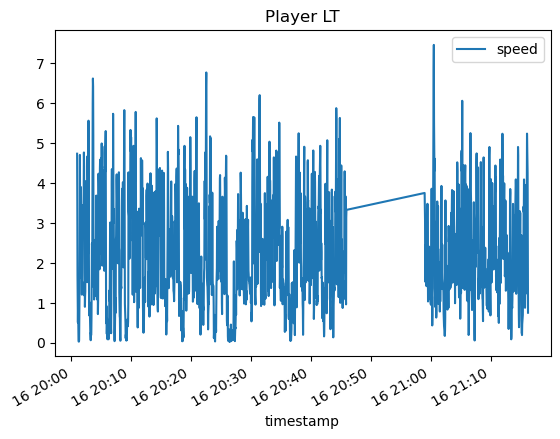

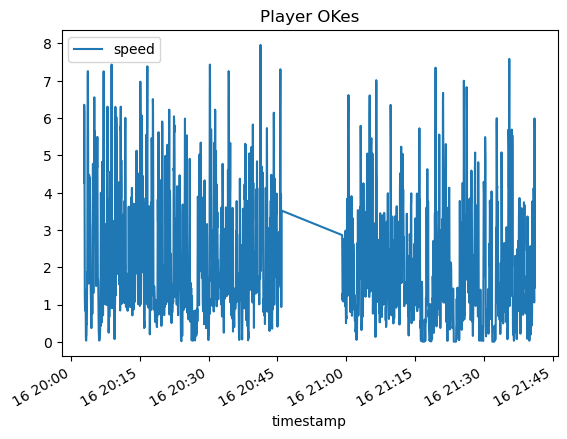

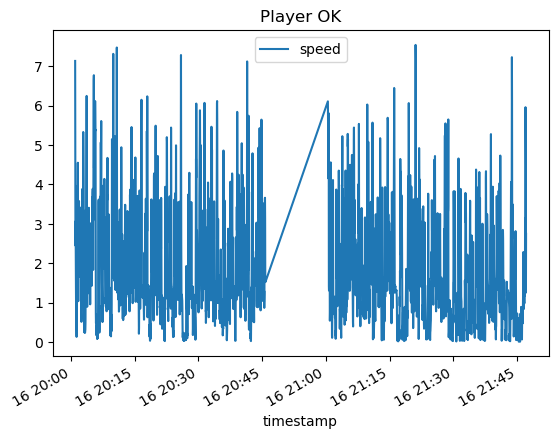

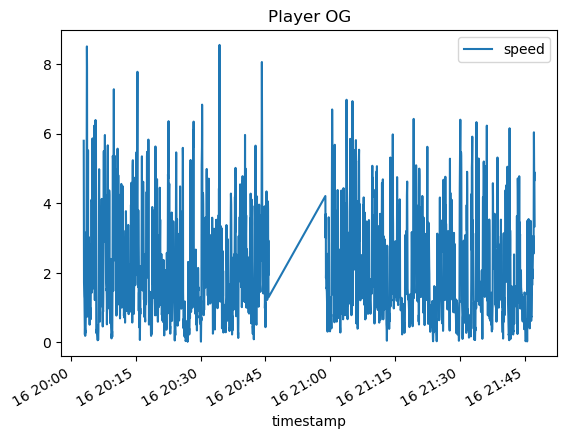

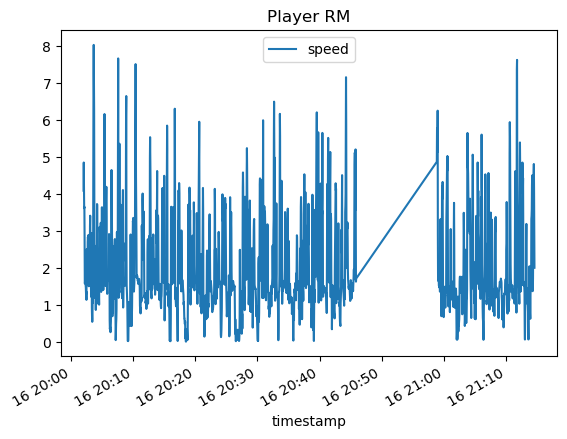

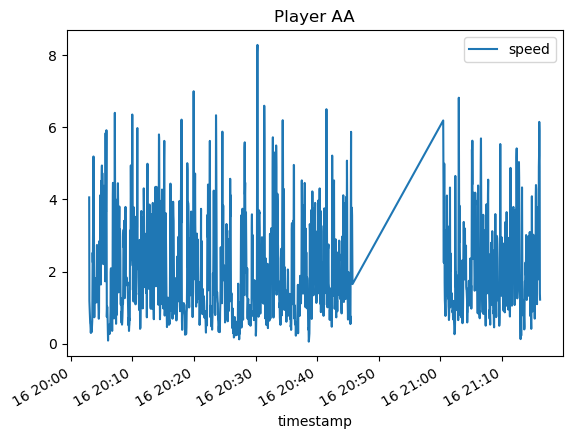

In [7]:
for i in range(42):
    processed[processed["track_id"] == i].set_index("timestamp").plot(y="speed")
    #player name as title, set timestamp as index, and plot speed over time

    plt.title(f"Player {processed[processed['track_id'] == i]["player"].iloc[0]}")

In [ ]:
processed["id"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41])

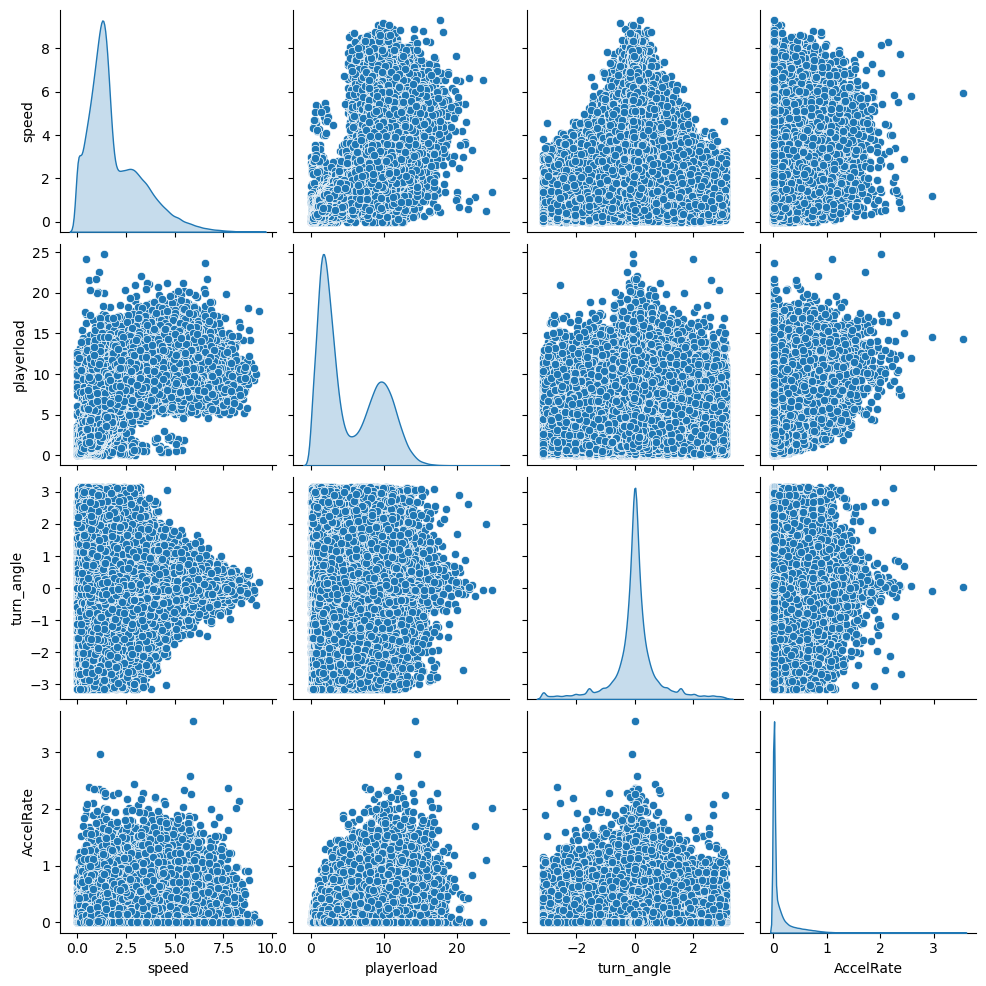

In [ ]:
sns.pairplot(processed[["speed", "playerload", "turn_angle", "AccelRate"]], kind="scatter", diag_kind="kde")

<Axes: >

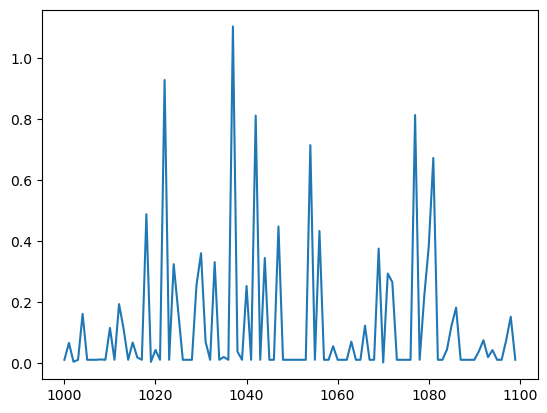

In [ ]:
processed["AccelRate"][1000:1100].plot()

<Axes: >

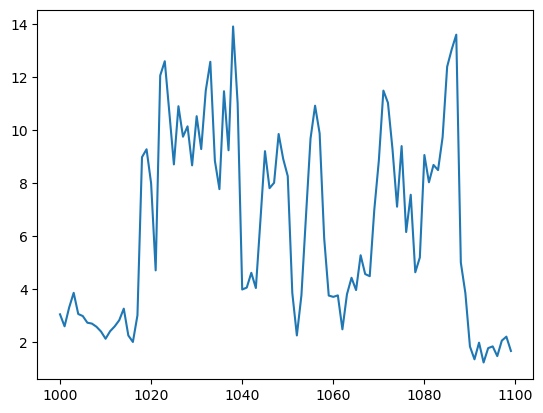

In [ ]:
processed["playerload"][1000:1100].plot()

In [ ]:
processed["AccelRate_cumsum"] = processed["AccelRate"].cumsum()
processed["playerload_cumsum"] = processed["playerload"].cumsum()

In [ ]:
processed.loc[processed["id"] == 0, "playerload"].sum()

np.float64(31280.94141564327)

<Axes: >

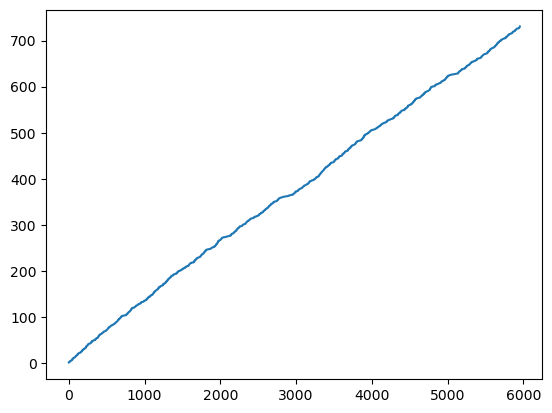

In [ ]:
processed.loc[processed["id"] == 0, "AccelRate_cumsum"].plot()

<Axes: >

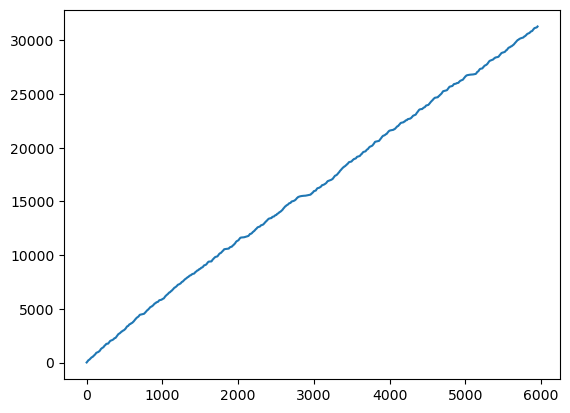

In [ ]:
processed.loc[processed["id"] == 0, "playerload_cumsum"].plot()

(-0.1, 5.0)

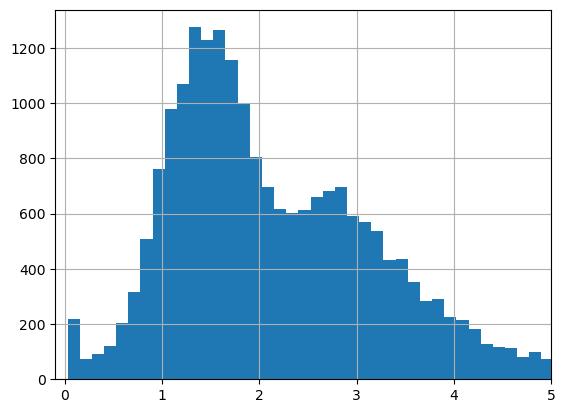

In [ ]:
processed["playerload"].hist(bins=100).set_xlim((-0.1, 5))

In [ ]:
processed["playerload"].sum()

np.float64(45401.85200866756)

<Axes: >

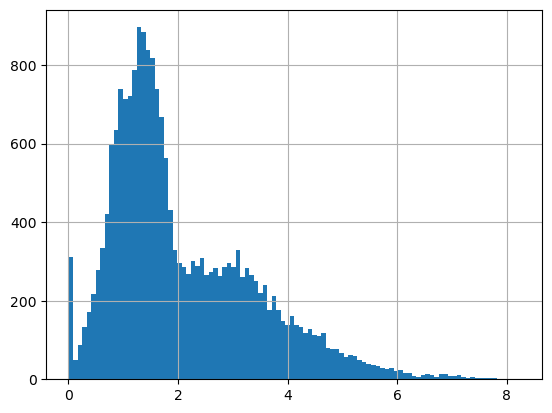

In [ ]:
processed["speed"].hist(bins=100)

<Axes: >

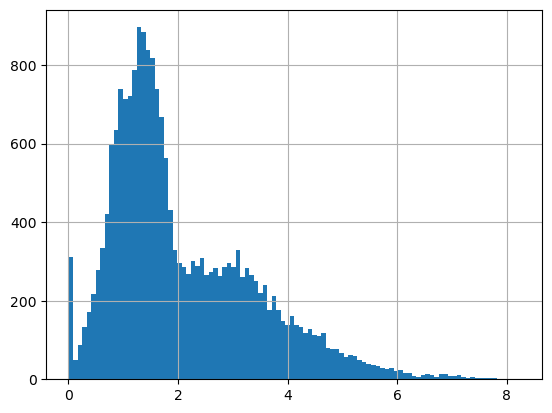

In [ ]:
processed["speed"].hist(bins=100)

In [ ]:
import pandas as pd

speed = processed["speed"]

# Boolean mask for zero speed
is_zero = speed <= 0.5

# Create segment IDs for continuous zero runs
zero_segments = (is_zero & ~is_zero.shift(fill_value=False)).cumsum()

# Keep only zero-speed rows
zero_speed_data = processed[is_zero].copy()
zero_speed_data["segment_id"] = zero_segments[is_zero]


In [ ]:
segment_lengths = zero_speed_data.groupby("segment_id").size()
segment_lengths

segment_id
1       1
2      21
3       2
4       2
5       1
       ..
267     2
268     8
269     1
270    15
271     1
Length: 271, dtype: int64

In [ ]:
segment_bounds = zero_speed_data.groupby("segment_id").apply(
    lambda g: pd.Series({
        "start": g.index[0],
        "end": g.index[-1],
        "length": len(g)
    })
)


C:\Users\jussi\AppData\Local\Temp\ipykernel_42236\1900701220.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  segment_bounds = zero_speed_data.groupby("segment_id").apply(


In [ ]:
segment_bounds["duration"] = (
    segment_bounds["end"] - segment_bounds["start"]
)

In [ ]:
(processed["speed"] <= 0.001).sum()/len(processed)

np.float64(0.0)

In [ ]:
real_stops = segment_bounds[segment_bounds["length"] >= 5]

In [ ]:
# Number of stops
len(segment_bounds)

# Longest stop
segment_bounds["length"].max()

# Average stop duration
segment_bounds["length"].mean()

# Histogram of stop lengths
segment_bounds["length"].value_counts()


length
1     153
2      41
3      15
4      15
5       7
6       6
7       5
9       4
8       4
14      2
13      2
21      2
10      2
17      2
24      1
16      1
23      1
30      1
28      1
22      1
59      1
51      1
12      1
11      1
15      1
Name: count, dtype: int64

In [ ]:
processed["speed"].describe()

count    20759.000000
mean         2.085419
std          1.320388
min          0.000010
25%          1.137120
50%          1.656902
75%          2.911246
max          8.235399
Name: speed, dtype: float64

In [ ]:
raw_data_file = RAW_DATA_DIR / "raw_n12_m17.csv"

processed = pd.read_csv(processed_data_file)
raw1 = pd.read_csv(raw_data_file)

(raw1[" Speed"] < 0.1).sum()/len(raw1)

np.float64(0.09809665646531267)

<Axes: >

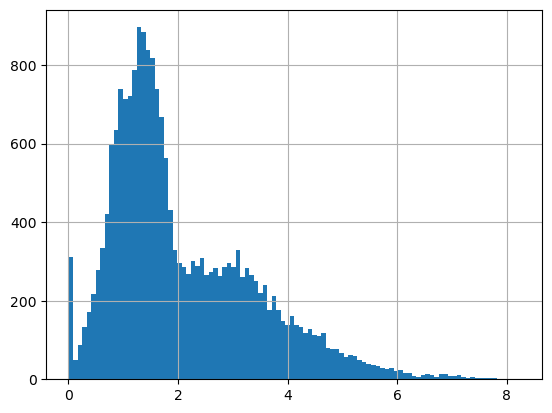

In [ ]:
processed["speed"].hist(bins=100)

In [ ]:
(processed["speed"] == 0).sum()

np.int64(0)

In [ ]:
processed = processed[processed["player_id"] == 18]

<Axes: >

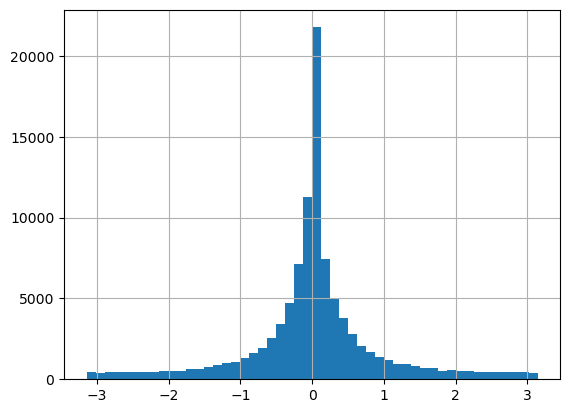

In [35]:
processed["turn_angle"].hist(bins=50)

In [37]:
# fit a von mises distribution to the turn_angle data
import numpy as np
from scipy.stats import vonmises

angles = processed["turn_angle"]

# Remove NaNs if necessary
angles = np.asarray(angles)
angles = angles[~np.isnan(angles)]

# Fit the distribution
kappa, loc, scale = vonmises.fit(angles, fscale=1)

print(f"kappa = {kappa:.3f}")
print(f"mean direction = {loc:.3f} rad ({np.degrees(loc):.1f}°)")

# x = kappa * cos(mu)
# y = kappa * sin(mu)
x = kappa * np.cos(loc)
y = kappa * np.sin(loc)
print(f"x = {x:.3f}, y = {y:.3f}")

kappa = 1.987
mean direction = 0.012 rad (0.7°)
x = 1.987, y = 0.023


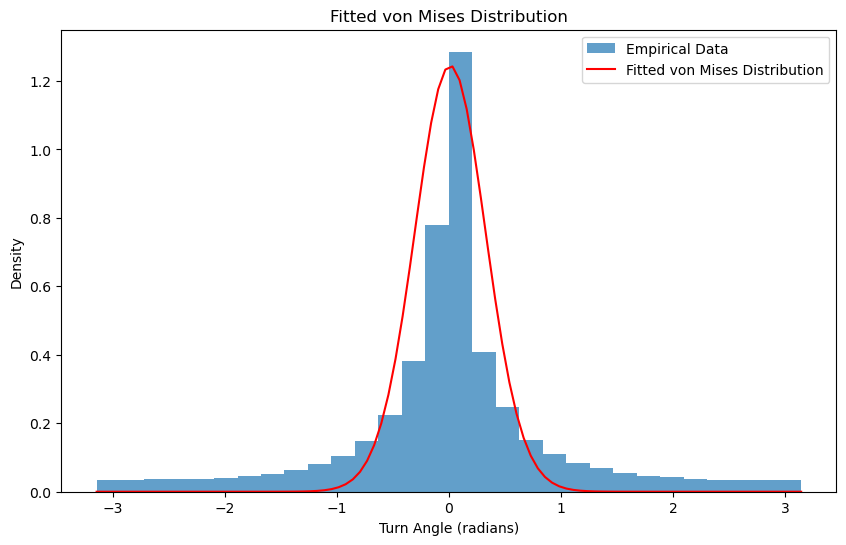

In [41]:
#Visualize the fitted distribution against the empirical data:
import matplotlib.pyplot as plt

# Create a range of angles for plotting the fitted distribution
angles_range = np.linspace(-np.pi, np.pi, 100)

# Compute the probability density of the fitted distribution
pdf_fitted = vonmises.pdf(angles_range, kappa=10, loc=loc, scale=scale)

# Plot the empirical data and the fitted distribution
plt.figure(figsize=(10, 6))
plt.hist(angles, bins=30, density=True, alpha=0.7, label='Empirical Data')
plt.plot(angles_range, pdf_fitted, 'r-', label='Fitted von Mises Distribution')
plt.xlabel('Turn Angle (radians)')
plt.ylabel('Density')
plt.title('Fitted von Mises Distribution')
plt.legend()
plt.show()

In [ ]:
# Correlation between accelrate and speed
processed[["speed", "accelrate"]].corr()

,speed,accelrate
speed,1.00000,0.78649
accelrate,0.78649,1.00000


In [ ]:
processed[processed["id"] == 0]["playerload"].sum()/10

np.float64(665.09083299709)

In [ ]:
processed[processed["id"] == 1]["playerload"].sum()/10

np.float64(589.3214206896924)

In [ ]:
processed[processed["id"] == 2]["playerload"].sum()/10

np.float64(666.6493849692739)

In [ ]:
for i in range(4):
    print(processed[processed["id"] == i]["playerload"].sum()/10)
    print(processed[processed["id"] == i].shape[0]/60)
    print("--")

665.09083299709
99.25
--
589.3214206896924
77.81666666666666
--
666.6493849692739
93.16666666666667
--
547.7562383015146
75.75
--


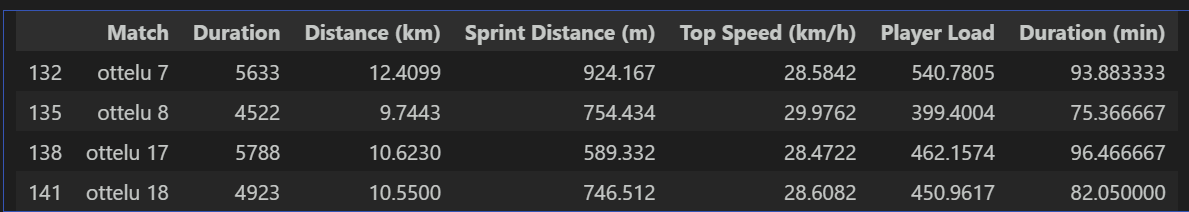

In [ ]:
import pandas as pd
import numpy as np

# create a datetime index every 0.1 s
time_index = pd.date_range(start="2026-02-05 12:00:00", periods=13, freq="100ms")

# speed data with some NaNs
speed = [5.0, np.nan, np.nan, 8.0, 9.0, np.nan, 10.0, np.nan, np.nan, np.nan, np.nan, np.nan, 14.0]

df = pd.DataFrame({"speed": speed}, index=time_index)
print(df)

                         speed
2026-02-05 12:00:00.000    5.0
2026-02-05 12:00:00.100    NaN
2026-02-05 12:00:00.200    NaN
2026-02-05 12:00:00.300    8.0
2026-02-05 12:00:00.400    9.0
2026-02-05 12:00:00.500    NaN
2026-02-05 12:00:00.600   10.0
2026-02-05 12:00:00.700    NaN
2026-02-05 12:00:00.800    NaN
2026-02-05 12:00:00.900    NaN
2026-02-05 12:00:01.000    NaN
2026-02-05 12:00:01.100    NaN
2026-02-05 12:00:01.200   14.0


In [13]:
import pandas as pd

In [14]:
processed = pd.read_csv(processed_data_file, index_col="timestamp")

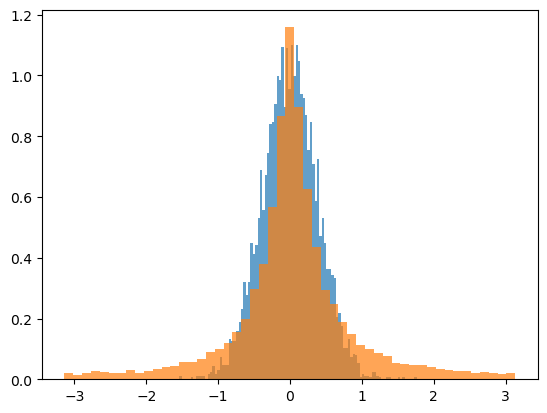

In [70]:
import numpy as np

n_sims = 5000
x_sim = np.random.normal(8, 1, n_sims)
y_sim = np.random.normal(0, 1, n_sims)
kappa_sim = np.sqrt(x_sim**2 + y_sim**2)
mu_sim = np.arctan2(y_sim, x_sim)

# simulate turn angles from von Mises(mu_sim, kappa_sim)
turn_angles = np.random.vonmises(mu_sim, kappa_sim)
import matplotlib.pyplot as plt

plt.hist(turn_angles, density=True, bins=100, alpha=0.7)
plt.hist(processed[processed["speed"] > 4]["turn_angle"], density=True, bins=51, alpha=0.7)
plt.show()